# 🎓 Instructor Effectiveness Modeling (EdTech Context)

**Role:** Data Science / AI Content Specialist Intern  **|**  **Format:** Jupyter / Google Colab notebook  **|**  **Libraries:** Python, pandas, numpy, scikit-learn, matplotlib, seaborn

---
## 0. Handbook digest — what is being asked and how this notebook answers it

**Business context.** An EdTech platform runs the *same course* across many batches, taught by *different instructors*. Each row of the dataset is **one course batch**; one instructor owns many rows. The company wants to understand **instructor effectiveness** from learner outcomes, engagement and feedback.

**Overall goal.** Define instructor effectiveness → aggregate batch data to instructor level → build an ML model that predicts an **effectiveness tier** (Low / Medium / High) → evaluate, interpret and critique it.

> The handbook states there is **no single correct answer** and that *reasoning matters more than accuracy*. So every decision below is explained, and limitations are stated openly.

### Handbook step → notebook section map

| Handbook requirement | Where it is answered |
|---|---|
| **Step 1** – EDA (distributions, relationships, correlations, missing values, anomalies, plots + short explanations) | Section 3 |
| **Step 2** – Define an Instructor Effectiveness Score and convert it to tiers; justify assumptions | Section 4 (score) and Section 5.4 (tiers) |
| **Step 3** – Aggregate batch → instructor; handle few / many batches; justify aggregation functions | Section 5 |
| **Step 4** – Train a classical ML model for the tier; feature selection / scaling encouraged | Section 6 |
| **Step 5** – Evaluation metrics, precision-vs-recall trade-offs, class imbalance | Section 7 |
| **Step 6** – Key features, plain-language explanation, product use | Section 8 |
| **Mandatory Questions 1–5** (in markdown cells) | Section 9 |

### Constraints from the handbook (and how they are respected)
| Constraint | Status |
|---|---|
| ❌ No LLMs / external APIs | ✅ None used |
| ❌ No external datasets | ✅ Only the supplied 2,000-row file |
| ❌ No AutoML | ✅ Plain scikit-learn models, hand-built pipelines |
| ✅ Allowed libraries only | ✅ pandas, numpy, scikit-learn, matplotlib, seaborn |
| ✅ Reproducible | ✅ One global random seed, no hidden state, runs top-to-bottom |
| ✅ Comment code and decisions | ✅ Comments in every code cell; decisions stated in markdown |

### Dataset dictionary (from the handbook)
* **Identifiers:** `batch_id`, `instructor_id`, `course_id`
* **Learner outcomes:** `completion_rate` (0–1), `dropout_rate` (0–1), `avg_score_improvement` (pre → post assessment), `avg_quiz_score`
* **Engagement:** `avg_watch_time` (normalised 0–1), `assignment_submission_rate`, `forum_activity_rate`
* **Feedback:** `avg_feedback_score` (1–5), `feedback_response_rate`

> ℹ️ **Data note.** The dataset is converted row-for-row into `instructor_effectiveness_dataset.csv` (2,000 rows × 12 columns). The PDF header contained a typo (`fedback_response_rate`) — the loader below normalises it to `feedback_response_rate`.

---
# 1. Setup & reproducibility
All imports are standard and permitted. A single `RANDOM_STATE` is used everywhere so results are reproducible.

In [1]:
# ---- Imports (only allowed libraries) -------------------------------------------------
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, cohen_kappa_score,
                             make_scorer, precision_recall_curve)
from sklearn.inspection import permutation_importance

# ---- Global settings ------------------------------------------------------------------
warnings.filterwarnings("ignore")          # keep the notebook output clean
RANDOM_STATE = 42                          # one seed for the whole notebook
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("Setup complete.")

Setup complete.


---
# 2. Load & validate the data
I load the CSV, normalise column names, and run **assertions** (schema, ranges, unique IDs) so that any problem is caught immediately rather than silently corrupting later steps.

In [2]:
# ---- Locate the CSV (works locally, in Colab, or from a mounted drive) ----------------
FILE_NAME = "instructor_effectiveness_dataset.csv"
candidate_paths = [FILE_NAME,
                   f"/content/{FILE_NAME}",                 # Google Colab upload folder
                   f"/content/drive/MyDrive/{FILE_NAME}",   # Colab + Google Drive
                   f"/mnt/user-data/outputs/{FILE_NAME}"]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Place '{FILE_NAME}' next to this notebook (or upload it to Colab's /content).")

raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.str.strip()
raw = raw.rename(columns={"fedback_response_rate": "feedback_response_rate"})   # fix header typo

# ---- Column groups used throughout the notebook ---------------------------------------
ID_COLS         = ["batch_id", "instructor_id", "course_id"]
OUTCOME_COLS    = ["completion_rate", "dropout_rate", "avg_score_improvement", "avg_quiz_score"]
ENGAGEMENT_COLS = ["avg_watch_time", "assignment_submission_rate", "forum_activity_rate"]
FEEDBACK_COLS   = ["avg_feedback_score", "feedback_response_rate"]
NUMERIC_COLS    = OUTCOME_COLS + ENGAGEMENT_COLS + FEEDBACK_COLS

# ---- Validation (fail loudly if the data is not what I expect) -----------------------
assert set(ID_COLS + NUMERIC_COLS) <= set(raw.columns), "Missing expected columns"
assert raw["batch_id"].is_unique, "batch_id should be unique"
assert raw[NUMERIC_COLS].notna().all().all(), "Unexpected missing values"
assert raw["avg_feedback_score"].between(1, 5).all(), "Feedback score outside 1-5"
for c in ["completion_rate", "dropout_rate", "avg_watch_time", "assignment_submission_rate",
          "forum_activity_rate", "feedback_response_rate"]:
    assert raw[c].between(0, 1).all(), f"{c} outside [0, 1]"

print(f"Loaded {raw.shape[0]:,} batches x {raw.shape[1]} columns from: {DATA_PATH}")
print(f"Instructors: {raw.instructor_id.nunique()} | Courses: {raw.course_id.nunique()}")
raw.head()

Loaded 2,000 batches x 12 columns from: instructor_effectiveness_dataset.csv
Instructors: 120 | Courses: 25


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.3000,14.2260,73.5465,0.6474,0.7746,0.7909,0.1084,3.7662,0.5332
1,B_0354,I_119,C_06,0.6572,22.8711,77.3123,0.4251,0.4949,0.9986,0.2805,5.0000,0.7341
2,B_1334,I_050,C_03,0.3000,16.0875,79.5637,0.7000,0.9779,0.8073,0.2070,3.5174,0.6814
3,B_0906,I_024,C_21,0.6395,24.2607,99.2953,0.3347,0.8465,0.5446,0.3064,4.2076,1.0000
4,B_1290,I_001,C_08,0.5273,31.0816,99.3934,0.5211,0.9175,0.8659,0.2523,4.4262,0.6967


---
# 3. Step 1 — Exploratory Data Analysis (EDA)
Goals (from the handbook): explore **distributions and relationships**, identify **correlations, missing values and anomalies**, and highlight **early observations** with plots and short explanations.

## 3.1 Structure and summary statistics

In [3]:
df = raw.copy()                                   # working copy; `raw` stays untouched
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes.to_string())
print("\nSummary statistics:")
df[NUMERIC_COLS].describe().T

Shape: (2000, 12)

Data types:
batch_id                          str
instructor_id                     str
course_id                         str
completion_rate               float64
avg_score_improvement         float64
avg_quiz_score                float64
dropout_rate                  float64
avg_watch_time                float64
assignment_submission_rate    float64
forum_activity_rate           float64
avg_feedback_score            float64
feedback_response_rate        float64

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
completion_rate,"2,000.0000",0.6028,0.1597,0.3000,0.4893,0.6031,0.7128,0.9800
dropout_rate,"2,000.0000",0.3949,0.1627,0.0200,0.2800,0.3948,0.5114,0.7000
avg_score_improvement,"2,000.0000",27.0358,5.7166,6.1592,23.1247,26.9386,30.8856,40.0000
avg_quiz_score,"2,000.0000",77.9561,10.6956,40.3867,70.8976,78.0206,85.4443,100.0000
avg_watch_time,"2,000.0000",0.7765,0.1452,0.2874,0.6751,0.7803,0.8942,1.0000
assignment_submission_rate,"2,000.0000",0.7532,0.1481,0.2511,0.6521,0.7564,0.8565,1.0000
forum_activity_rate,"2,000.0000",0.2503,0.1006,0.0000,0.1798,0.2498,0.3192,0.6411
avg_feedback_score,"2,000.0000",4.2071,0.4192,2.6399,3.9190,4.2060,4.5034,5.0000
feedback_response_rate,"2,000.0000",0.7365,0.1494,0.2599,0.6333,0.7372,0.8459,1.0000


## 3.2 Data quality: missing values, duplicates, boundary values, outliers
Things I check and why:
* **Missing values / duplicates** – basic hygiene.
* **Boundary values** – many metrics are bounded (0–1, 1–5, ≤100). A pile-up of rows *exactly at* a boundary is a sign of **clipping/truncation** in the data pipeline and affects how I should treat the variable.
* **Completion + dropout** – these should be (almost) complements. If they are not, they measure slightly different things.
* **IQR outliers** – extreme but valid values are *kept* (they are real batches); I only note them.

In [4]:
# ---- Missing values & duplicates -----------------------------------------------------
print("Missing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows:", df.duplicated().sum(), "| Duplicate batch_ids:", df.batch_id.duplicated().sum())

# ---- Boundary pile-ups (possible clipping) -------------------------------------------
rows = []
for c in NUMERIC_COLS:
    lo, hi = df[c].min(), df[c].max()
    rows.append({"column": c, "min": lo, "rows_at_min": int((df[c] == lo).sum()),
                 "max": hi, "rows_at_max": int((df[c] == hi).sum())})
boundary = pd.DataFrame(rows).set_index("column")
print("\nValues sitting exactly on the observed min / max (2,000 rows in total):")
display(boundary)

# ---- Are completion and dropout complements? -----------------------------------------
s = df.completion_rate + df.dropout_rate
print(f"\ncompletion_rate + dropout_rate: mean={s.mean():.3f}, min={s.min():.3f}, max={s.max():.3f}")
print(f"Correlation(completion, dropout) = {df.completion_rate.corr(df.dropout_rate):.3f}")

# ---- IQR outlier counts (kept, but noted) --------------------------------------------
q1, q3 = df[NUMERIC_COLS].quantile(0.25), df[NUMERIC_COLS].quantile(0.75)
iqr = q3 - q1
outliers = ((df[NUMERIC_COLS] < (q1 - 1.5 * iqr)) | (df[NUMERIC_COLS] > (q3 + 1.5 * iqr))).sum()
print("\nIQR-rule outliers per column:\n", outliers.to_string())

Missing values per column:
 batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0

Duplicate rows: 0 | Duplicate batch_ids: 0

Values sitting exactly on the observed min / max (2,000 rows in total):


,min,rows_at_min,max,rows_at_max
column,,,,
completion_rate,0.3000,77,0.9800,32
dropout_rate,0.0200,23,0.7000,72
avg_score_improvement,6.1592,1,40.0000,35
avg_quiz_score,40.3867,1,100.0000,37
avg_watch_time,0.2874,1,1.0000,149
assignment_submission_rate,0.2511,1,1.0000,125
forum_activity_rate,0.0000,14,0.6411,1
avg_feedback_score,2.6399,1,5.0000,67
feedback_response_rate,0.2599,1,1.0000,94



completion_rate + dropout_rate: mean=0.998, min=0.829, max=1.160
Correlation(completion, dropout) = -0.953

IQR-rule outliers per column:
 completion_rate                0
dropout_rate                   0
avg_score_improvement          6
avg_quiz_score                11
avg_watch_time                 3
assignment_submission_rate     6
forum_activity_rate            5
avg_feedback_score            11
feedback_response_rate         5


**What I learn from 3.2**
* ✅ No missing values, no duplicates, all IDs are unique.
* ⚠️ **Clipping is clearly present.** For example `completion_rate` has a floor at 0.30 and a ceiling at 0.98, `dropout_rate` is capped at 0.70 (and floored at 0.02), `avg_score_improvement` is capped at 40, `avg_quiz_score` at 100 and `avg_feedback_score` at 5. These pile-ups mean the *true* extremes are hidden — differences among the very best/worst batches are compressed.
* ⚠️ **Completion and dropout are near-complements but not exact** (their sum ranges roughly 0.83–1.16). They carry almost the same information, so counting both as separate "signals" would **double-count** retention.
* Outliers exist but are plausible values, so they are **kept**; using z-scores and means/medians later keeps their influence modest.

## 3.3 Distributions of every metric
Histograms with a density curve. I look for skew, bounded/clipped shapes, and whether metrics are on very different scales (which matters for scaling later).

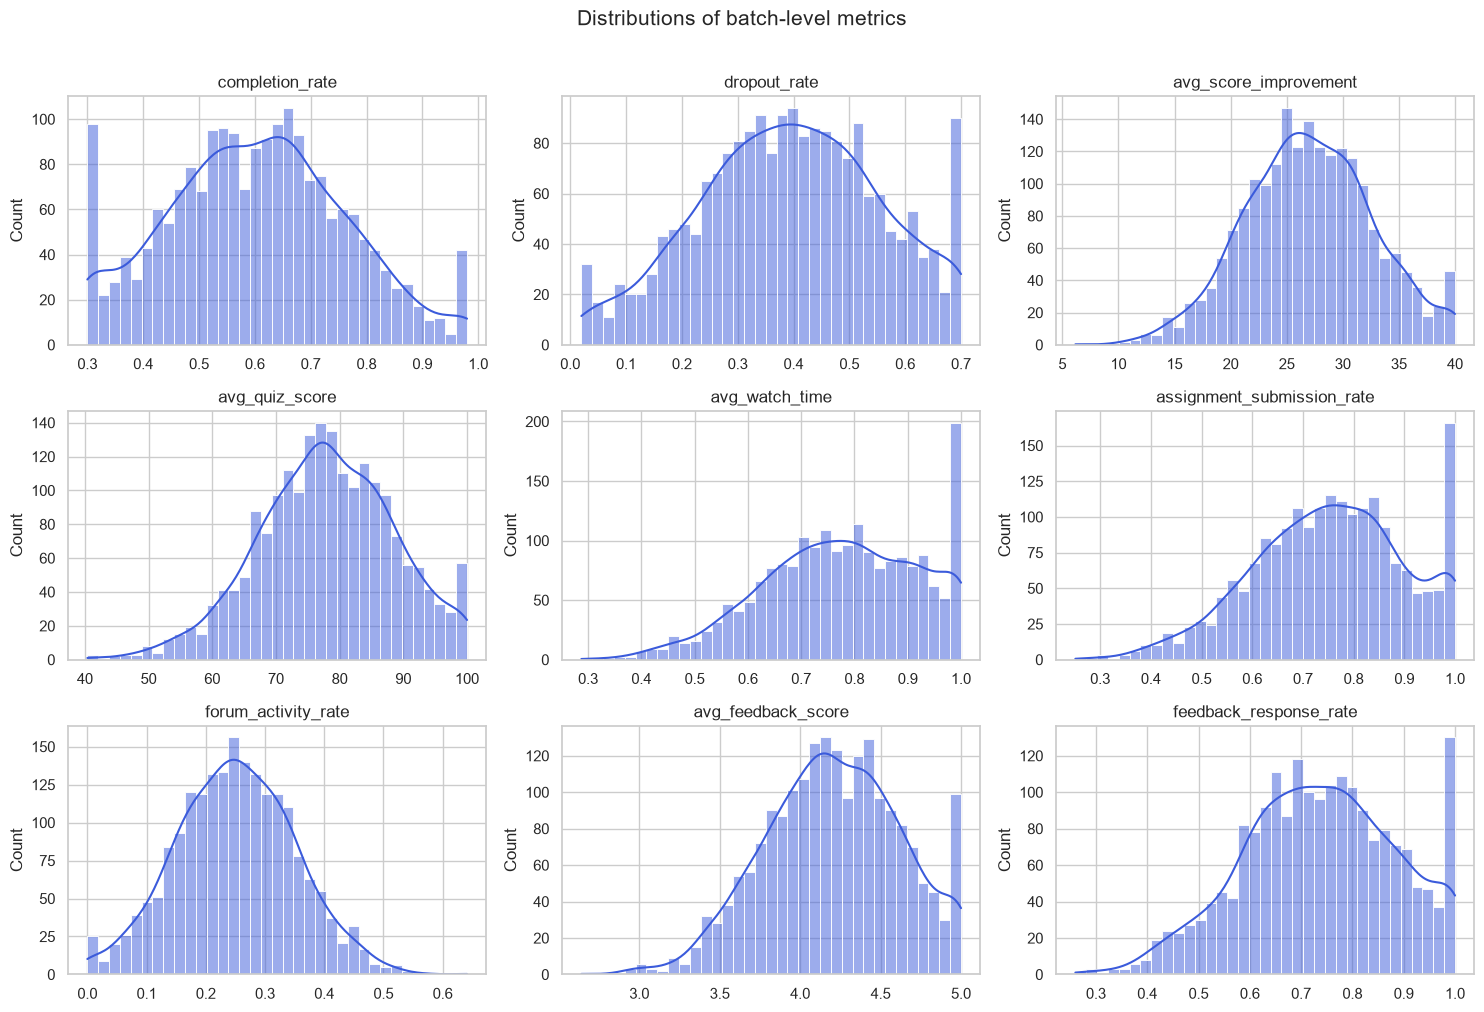

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.histplot(df[col], kde=True, bins=35, ax=ax, color="#3b5bdb")
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distributions of batch-level metrics", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

**Reading the distributions**
* Outcome metrics (`completion_rate`, `avg_score_improvement`, `avg_quiz_score`) are roughly bell-shaped with **spikes at the clipping limits**.
* `avg_watch_time` and `assignment_submission_rate` are **left-skewed** with spikes at 1.0 (many batches have near-perfect engagement).
* `forum_activity_rate` is low (centred around 0.25) – forums are used by a minority.
* Metrics sit on **very different scales** (0–1 vs 0–100 vs 1–5), so **scaling is required** before comparing or combining them.

## 3.4 Relationships between variables (correlations)
Pearson correlation shows linear association; I also list the strongest pairs.

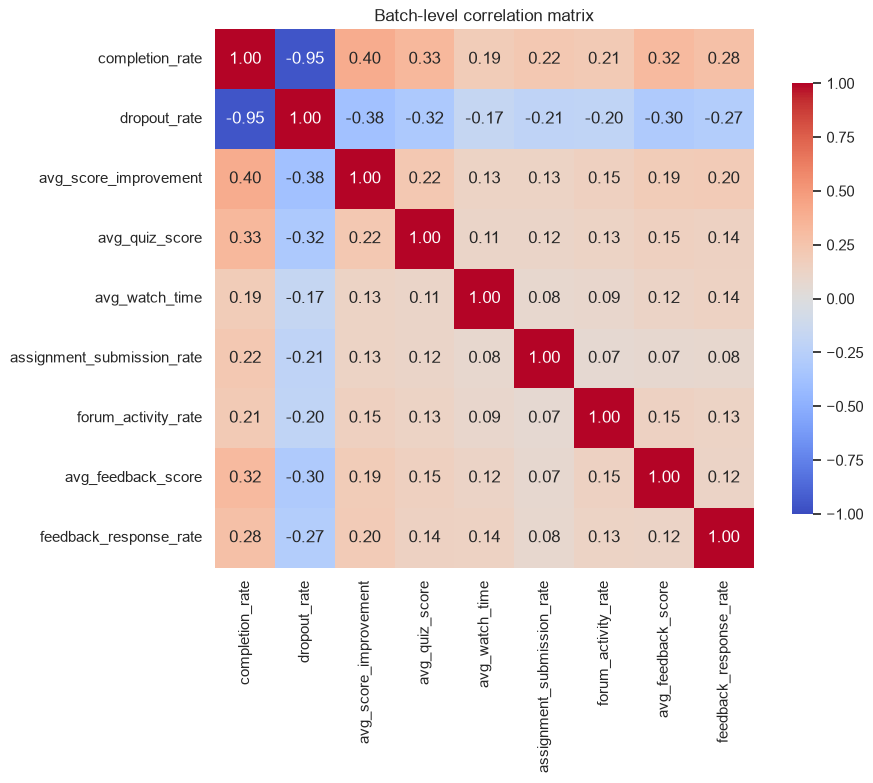

Top 8 strongest relationships:


,var_1,var_2,corr
0,completion_rate,dropout_rate,-0.9535
1,completion_rate,avg_score_improvement,0.4042
2,dropout_rate,avg_score_improvement,-0.3814
3,completion_rate,avg_quiz_score,0.3333
4,completion_rate,avg_feedback_score,0.3154
5,dropout_rate,avg_quiz_score,-0.3152
6,dropout_rate,avg_feedback_score,-0.3006
7,completion_rate,feedback_response_rate,0.2795


In [6]:
corr = df[NUMERIC_COLS].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            cbar_kws={"shrink": 0.8})
plt.title("Batch-level correlation matrix")
plt.tight_layout()
plt.show()

# Strongest absolute pairs (upper triangle only, so each pair appears once)
pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("corr").reset_index()
             .rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pairs["abs_corr"] = pairs["corr"].abs()
print("Top 8 strongest relationships:")
pairs.sort_values("abs_corr", ascending=False).head(8).drop(columns="abs_corr").reset_index(drop=True)

**Reading the correlations**
* `completion_rate` ↔ `dropout_rate` ≈ **−0.95** → near-duplicates (see 3.2).
* All other relationships are **positive but moderate** at batch level (roughly 0.1–0.4). Completion is the most "connected" metric: it relates to score improvement, quiz score and feedback.
* Engagement metrics correlate only weakly with each other (≈0.07–0.09) – watching, submitting and posting are *different behaviours*, not one underlying thing.
* Weak batch-level correlations suggest **lots of batch-level noise** – which is exactly why I will aggregate to instructor level (see 3.7).

## 3.5 Dataset structure: how many batches / courses per instructor?
This drives the aggregation strategy (Step 3): *do instructors with few batches exist? Do instructors teach several courses?*

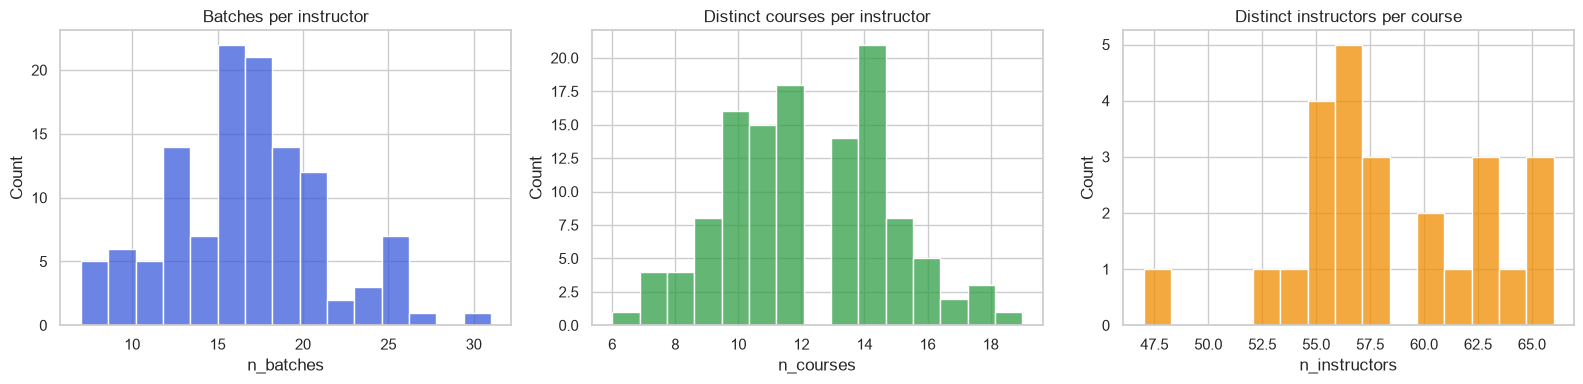

             min     25%     50%     75%     max
n_batches 7.0000 13.7500 17.0000 19.0000 31.0000
n_courses 6.0000 10.0000 12.0000 14.0000 19.0000

Instructors with fewer than 10 batches: 6 | fewer than 5: 0
Fewest instructors on any single course: 47


In [7]:
inst_counts = df.groupby("instructor_id").agg(n_batches=("batch_id", "count"), n_courses=("course_id", "nunique"))
course_counts = df.groupby("course_id").agg(n_batches=("batch_id", "count"), n_instructors=("instructor_id", "nunique"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(inst_counts.n_batches, bins=15, ax=axes[0], color="#3b5bdb"); axes[0].set_title("Batches per instructor")
sns.histplot(inst_counts.n_courses, bins=15, ax=axes[1], color="#2f9e44");  axes[1].set_title("Distinct courses per instructor")
sns.histplot(course_counts.n_instructors, bins=15, ax=axes[2], color="#f08c00"); axes[2].set_title("Distinct instructors per course")
plt.tight_layout(); plt.show()

print(inst_counts.describe().T[["min", "25%", "50%", "75%", "max"]])
print("\nInstructors with fewer than 10 batches:", int((inst_counts.n_batches < 10).sum()),
      "| fewer than 5:", int((inst_counts.n_batches < 5).sum()))
print("Fewest instructors on any single course:", int(course_counts.n_instructors.min()))

**Reading the structure**
* **120 instructors, 25 courses, 2,000 batches** → ≈ 16.7 batches per instructor (range 7–31). Nobody is a one-batch instructor, but **6 instructors have fewer than 10 batches**, so their averages are noisier.
* Instructors teach **many different courses** (typically ~12 of 25), and every course is taught by many instructors (at least 47 per course). That is good news: it lets us **separate instructor effects from course effects**, because I can compare instructors *on the same course*.

## 3.6 Is it the *instructor* or the *course*? (confounding check)
If some courses are simply harder, raw outcomes would punish instructors for the courses they were assigned. I measure how much of each metric's variation is explained by **course** versus by **instructor** using *adjusted* η² (R² corrected for the number of groups, so groups with many levels are not unfairly favoured).

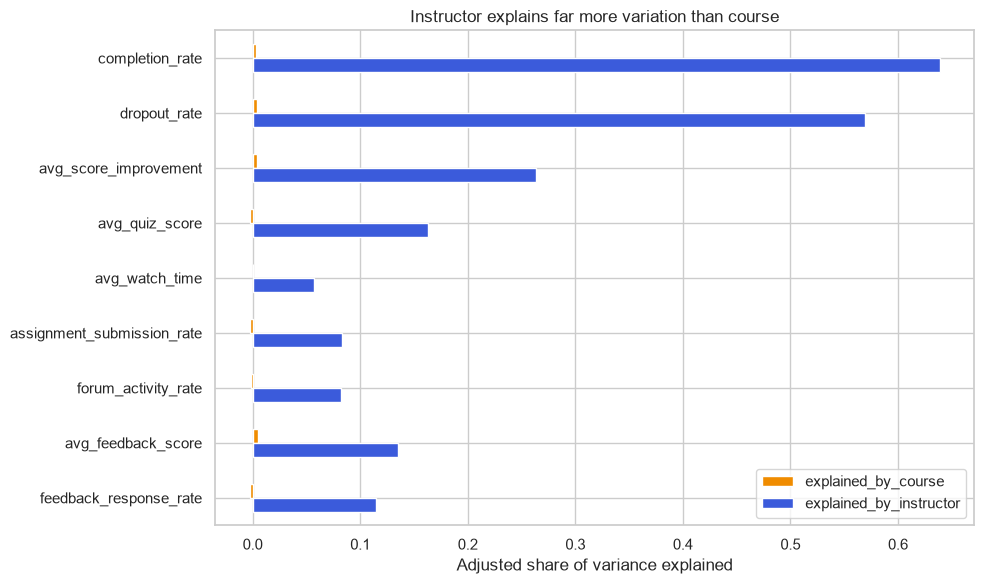

,explained_by_course,explained_by_instructor
completion_rate,0.0035,0.6386
dropout_rate,0.0038,0.5689
avg_score_improvement,0.0039,0.2632
avg_quiz_score,-0.0022,0.1634
avg_watch_time,0.0002,0.0567
assignment_submission_rate,-0.0028,0.0834
forum_activity_rate,-0.0020,0.0819
avg_feedback_score,0.0052,0.1354
feedback_response_rate,-0.0028,0.1143


In [8]:
def adjusted_eta_squared(frame, col, by):
    """Share of variance in `col` explained by group `by`, adjusted for the number of groups."""
    grand = frame[col].mean()
    ss_between = ((frame.groupby(by)[col].transform("mean") - grand) ** 2).sum()
    ss_total = ((frame[col] - grand) ** 2).sum()
    n, k = len(frame), frame[by].nunique()
    r2 = ss_between / ss_total
    return 1 - (1 - r2) * (n - 1) / (n - k)

variance_table = pd.DataFrame({
    "explained_by_course":     [adjusted_eta_squared(df, c, "course_id")     for c in NUMERIC_COLS],
    "explained_by_instructor": [adjusted_eta_squared(df, c, "instructor_id") for c in NUMERIC_COLS],
}, index=NUMERIC_COLS)

variance_table.plot.barh(figsize=(10, 6), color=["#f08c00", "#3b5bdb"])
plt.xlabel("Adjusted share of variance explained"); plt.title("Instructor explains far more variation than course")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()
variance_table

**Reading the result.** Course explains **essentially nothing** (< 1 % of variance for every metric), while the instructor explains anywhere from ~6 % (watch time) to ~64 % (completion rate) — with outcomes (completion 64 %, dropout 57 %, improvement 26 %, quiz 16 %) carrying the strongest instructor signal. So the data contain a **real, persistent instructor signal** – and course difficulty is a *minor* confounder. I still adjust for course in the score (Section 4) because it is cheap, principled and protects instructors who happen to teach harder courses.

## 3.7 Why aggregate? Batch-level noise vs instructor-level signal
Averaging many batches per instructor cancels random batch-to-batch noise. The same two metrics are compared at both levels.

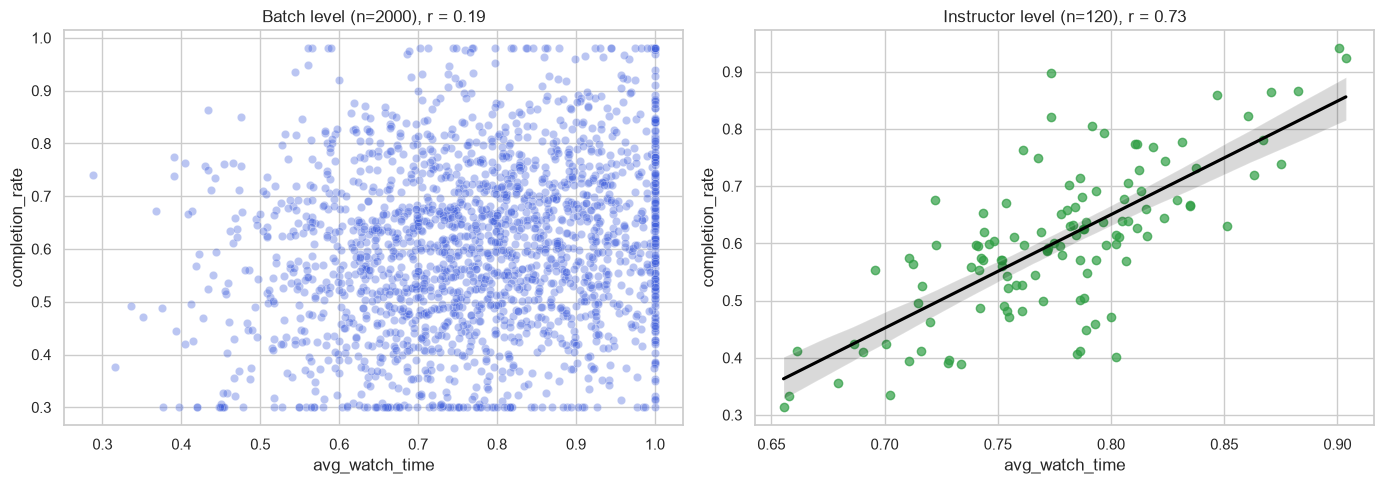

Average |correlation| between the 9 metrics:
  batch level      : 0.21
  instructor level : 0.72


In [9]:
inst_means = df.groupby("instructor_id")[NUMERIC_COLS].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="avg_watch_time", y="completion_rate", alpha=0.35, ax=axes[0], color="#3b5bdb")
axes[0].set_title(f"Batch level (n=2000), r = {df.avg_watch_time.corr(df.completion_rate):.2f}")
sns.regplot(data=inst_means, x="avg_watch_time", y="completion_rate", ax=axes[1],
            scatter_kws={"alpha": 0.7, "color": "#2f9e44"}, line_kws={"color": "black"})
axes[1].set_title(f"Instructor level (n=120), r = {inst_means.avg_watch_time.corr(inst_means.completion_rate):.2f}")
plt.tight_layout(); plt.show()

print("Average |correlation| between the 9 metrics:")
off = lambda m: m.where(~np.eye(len(m), dtype=bool)).abs().stack().mean()
print(f"  batch level      : {off(df[NUMERIC_COLS].corr()):.2f}")
print(f"  instructor level : {off(inst_means.corr()):.2f}")

## 3.8 Early observations (summary of Step 1)
1. **Clean but clipped data** – no missing values; several metrics are truncated at hard limits (completion 0.30/0.98, dropout 0.70/0.02, improvement 40, quiz 100, feedback 5).
2. **Redundancy** – `completion_rate` and `dropout_rate` are ~95 % anti-correlated; treat them as **one "retention" signal**.
3. **Different scales** – scaling/standardising is necessary.
4. **Instructor effect ≫ course effect** – good: it supports the whole project idea. Course adjustment is still sensible but, in this data, not decisive.
5. **Noisy batches, clear instructor patterns** – correlations strengthen markedly when averaged per instructor (average |r| ≈ 0.21 → ≈ 0.72), so **aggregation is essential**.
6. **Engagement behaviours are only weakly linked to each other**, so each deserves its own feature rather than one blended number.
7. **Selection bias risk** – `feedback_response_rate` varies a lot (some batches hear from only ~25 % of learners); feedback scores from low-response batches are less trustworthy.

---
# 4. Step 2 — Define the Instructor Effectiveness Score
> The handbook says there is *no predefined formula* — I must **justify our definition and assumptions**.

## 4.1 Design principles
**What does "effective" mean?** An effective instructor helps learners **actually learn**, **stay the course**, and **have a good experience** – *not* merely attract engaged or high-ability learners.

We therefore build the score from **two pillars** and keep **engagement out of the score**:

| Pillar | Metrics inside it | Why |
|---|---|---|
| **Learning outcomes (weight 70 %)** | `avg_score_improvement` (40 %), retention = completion & inverse dropout (35 %), `avg_quiz_score` (25 %) | Hard evidence of learning and persistence. *Improvement* is weighted highest because it is measured **pre → post**, so it partly controls for learners' starting level. `avg_quiz_score` is a *level*, which depends heavily on learner ability, so it gets the smallest outcome weight. Completion and dropout are merged into one retention signal to avoid double counting (r ≈ −0.95). |
| **Learner satisfaction (weight 30 %)** | `avg_feedback_score`, down-weighted when `feedback_response_rate` is low | Captures experience, but feedback is subjective and can be biased (popularity, grading leniency) and unreliable when few learners respond – hence the lower weight and the **reliability adjustment**. |

**Why engagement is *not* in the score.** Watch time, assignment submission and forum activity describe *how learners behave*, which is partly *caused* by the instructor and partly by the learners themselves (a **mediator / confounder**). If I put them inside the score **and** then use them as model inputs, the model would just re-learn our own formula (circular, "target leakage"). Keeping them as **predictors** instead lets us ask a useful, honest question:

> *"Do the engagement patterns I can observe early and cheaply tell us which instructors will turn out to be effective?"*

A sensitivity analysis in Section 5.5 shows what happens if these choices change.

## 4.2 Assumptions (explicit)
1. Higher improvement, completion, quiz score and feedback are *better*; higher dropout is *worse*.
2. Courses differ in difficulty, so every metric is **centred within its course** (compare an instructor with peers teaching the *same* course) and then divided by the overall standard deviation so metrics become comparable ("how many standard deviations better than course peers").
3. Feedback from a batch with a low response rate carries less information, so its z-score is **multiplied by the response rate** (shrinking unreliable feedback toward "average").
4. Learner mix (prior ability, motivation) is **not observed**; I cannot adjust for it (a limitation discussed in Section 9).
5. The weights are a **judgement call**, tested for robustness in Section 5.5.

Min instructors per course: 47 (centring would erase an instructor's effect only if a course had ~1 instructor)

Pillar correlations (batch level):


,pillar_outcomes,pillar_satisfaction,pillar_engagement,batch_score
pillar_outcomes,1.0000,0.2883,0.3331,0.9393
pillar_satisfaction,0.2883,1.0000,0.1724,0.5993
pillar_engagement,0.3331,0.1724,1.0000,0.3403
batch_score,0.9393,0.5993,0.3403,1.0000


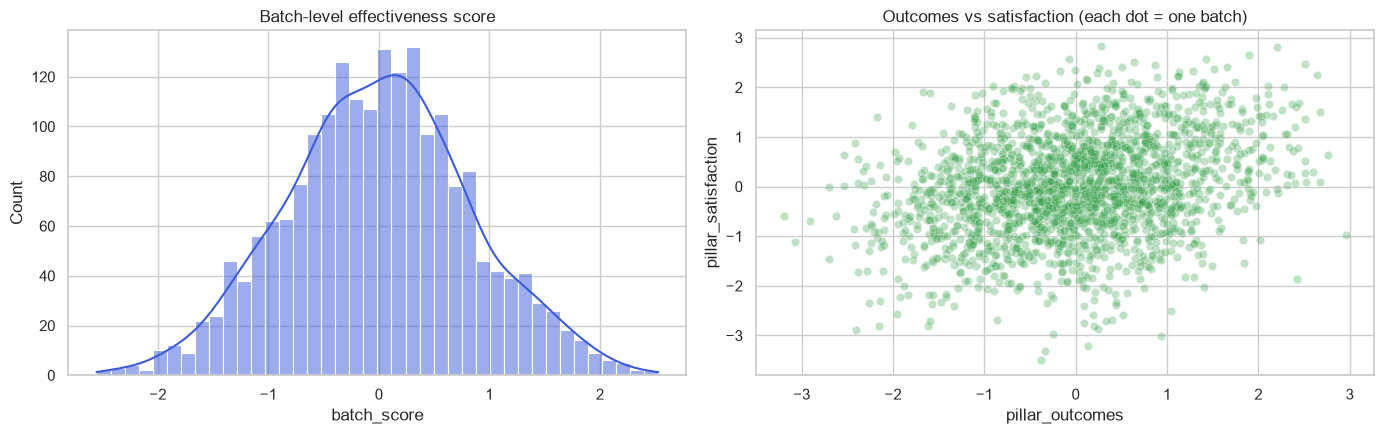

In [10]:
# =====================================================================================
# 4.3  Batch-level effectiveness score
# =====================================================================================
def zscore(s):
    """Standardise a series: mean 0, standard deviation 1 (population std)."""
    return (s - s.mean()) / s.std(ddof=0)

def course_centred_z(frame, col):
    """
    Course-adjusted z-score: (value - mean of the SAME course) / overall std.
    Interpretation: 'how far above/below the average batch of this course, in global SD units'.
    """
    course_mean = frame.groupby("course_id")[col].transform("mean")
    return (frame[col] - course_mean) / frame[col].std(ddof=0)

# ---- Safety check: course-centring is only meaningful if each course has many instructors
print("Min instructors per course:", df.groupby("course_id").instructor_id.nunique().min(),
      "(centring would erase an instructor's effect only if a course had ~1 instructor)")

# ---- Component z-scores (all course-adjusted; 'higher = better') ----------------------
df["z_improvement"] = course_centred_z(df, "avg_score_improvement")
df["z_quiz"]        = course_centred_z(df, "avg_quiz_score")
df["z_completion"]  = course_centred_z(df, "completion_rate")
df["z_dropout_inv"] = -course_centred_z(df, "dropout_rate")             # flip sign: lower dropout is better
df["z_retention"]   = (df["z_completion"] + df["z_dropout_inv"]) / 2     # merge the two near-duplicates
df["z_feedback"]    = course_centred_z(df, "avg_feedback_score")

# ---- Pillar 1: learning outcomes ------------------------------------------------------
W_OUTCOME_PARTS = {"z_improvement": 0.40, "z_retention": 0.35, "z_quiz": 0.25}
outcomes_raw = sum(w * df[c] for c, w in W_OUTCOME_PARTS.items())
df["pillar_outcomes"] = zscore(outcomes_raw)       # re-standardise so pillars are on the same scale

# ---- Pillar 2: satisfaction, reliability-adjusted -------------------------------------
# multiply by response rate: batches where few learners responded are pulled toward 'average'
satisfaction_raw = df["feedback_response_rate"] * df["z_feedback"]
df["pillar_satisfaction"] = zscore(satisfaction_raw)

# ---- (Reference only) engagement pillar: NOT in the score; used later in sensitivity checks
eng_raw = sum(course_centred_z(df, c) for c in ENGAGEMENT_COLS) / len(ENGAGEMENT_COLS)
df["pillar_engagement"] = zscore(eng_raw)

# ---- Final batch score = weighted combination of the two pillars ----------------------
PILLAR_WEIGHTS = {"pillar_outcomes": 0.70, "pillar_satisfaction": 0.30}
df["batch_score"] = sum(w * df[c] for c, w in PILLAR_WEIGHTS.items())

print("\nPillar correlations (batch level):")
display(df[["pillar_outcomes", "pillar_satisfaction", "pillar_engagement", "batch_score"]].corr())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["batch_score"], kde=True, bins=40, ax=axes[0], color="#3b5bdb")
axes[0].set_title("Batch-level effectiveness score")
sns.scatterplot(data=df, x="pillar_outcomes", y="pillar_satisfaction", alpha=0.3, ax=axes[1], color="#2f9e44")
axes[1].set_title("Outcomes vs satisfaction (each dot = one batch)")
plt.tight_layout(); plt.show()

**Sanity checks on the score.** Outcomes and satisfaction are positively but only moderately related (batch level), so each pillar contributes **distinct information** — the combined score is not just one metric in disguise. The batch score is roughly bell-shaped, so no extreme transformation was needed.

> The batch score is a *building block*. The handbook asks for an **instructor-level** score and tiers – these are produced next, after aggregation (Section 5), because an instructor's score should reflect *all* their batches and the *confidence* I have in them.

---
# 5. Step 3 — Aggregate batch data to instructor level
## 5.1 Strategy and justification
Each instructor owns 7–31 batches. We need **one row per instructor**. Key decisions:

| Decision | Choice | Why it makes sense |
|---|---|---|
| **Central tendency** | **Mean** of batch values (not sum) | Sums would reward instructors simply for teaching *more* batches. Means measure *quality per batch*. |
| **Few batches** | **Empirical-Bayes shrinkage**: pull an instructor's mean toward the global mean, *more strongly when n is small* | An average of 7 batches is noisier than an average of 30. Shrinkage stops a lucky/unlucky short run from producing an extreme score, and the amount of shrinkage is **estimated from the data**, not guessed. |
| **Minimum data rule** | Instructors with **< 5 batches are excluded** from modelling (none in this data, but the rule is coded); those with **< 10** are flagged "low confidence" | A hard floor protects the model; a soft flag keeps small-sample instructors visible without over-trusting them. |
| **Many batches** | No extra weighting (their mean is already stable); I add a **spread (std)** feature to capture *consistency* | A high-volume instructor should not be penalised, and an average can hide volatility. |
| **Spread** | **Standard deviation** of engagement metrics | Distinguishes steady instructors from erratic ones with the same mean. |
| **Context** | `n_batches`, `n_courses`, `course_diversity`, `course_baseline_mean` | Lets the model (and us) see whether experience, breadth, or an easier course mix matters. Experience is **not** assumed to matter – I test it. |
| **Time** | Not available | With timestamps I would add recency weighting / trend features. |

**Shrinkage formula.** For metric *x*, instructor *i* with *nᵢ* batches:
`shrunk_i = μ + Bᵢ · (mean_i − μ)`, where `Bᵢ = nᵢ / (nᵢ + k)` and `k = σ²_within / τ²_between` (typical batch noise divided by true spread between instructors; estimated by the method of moments). Large *n* → B≈1 (trust the instructor's own mean); small *n* → B smaller (lean on the global mean).

In [11]:
# =====================================================================================
# 5.2  Empirical-Bayes shrinkage helper
# =====================================================================================
MIN_BATCHES_TO_MODEL = 5    # hard floor: fewer batches -> not enough evidence, excluded
LOW_CONFIDENCE_BELOW = 10   # soft flag: included but marked low-confidence

def eb_shrunk_mean(frame, col, group="instructor_id"):
    """
    Return (shrunk instructor means, k) for `col`.
    k = within-instructor variance / between-instructor variance of true means.
    """
    g = frame.groupby(group)[col]
    n, means, mu = g.size(), g.mean(), frame[col].mean()
    sigma2 = g.var(ddof=1).mean()                           # typical batch-to-batch noise inside an instructor
    tau2 = max(means.var(ddof=1) - (sigma2 / n).mean(), 1e-9)   # true spread between instructors (noise removed)
    k = sigma2 / tau2
    B = n / (n + k)                                         # reliability weight in (0, 1)
    return mu + B * (means - mu), k

# ---- Apply the minimum-batches rule ---------------------------------------------------
batch_counts = df.groupby("instructor_id").size()
eligible = batch_counts[batch_counts >= MIN_BATCHES_TO_MODEL].index
print(f"Instructors kept: {len(eligible)} of {len(batch_counts)} (rule: >= {MIN_BATCHES_TO_MODEL} batches)")
dfm = df[df.instructor_id.isin(eligible)].copy()

# ---- Instructor-level score -----------------------------------------------------------
inst = pd.DataFrame({"n_batches": dfm.groupby("instructor_id").size()})
inst["n_courses"]       = dfm.groupby("instructor_id").course_id.nunique()
inst["course_diversity"] = inst["n_courses"] / inst["n_batches"]        # 1 = every batch a different course
inst["low_confidence"]  = inst["n_batches"] < LOW_CONFIDENCE_BELOW
inst["score_raw_mean"]  = dfm.groupby("instructor_id")["batch_score"].mean()
inst["effectiveness_score"], K_SCORE = eb_shrunk_mean(dfm, "batch_score")

B_all = inst["n_batches"] / (inst["n_batches"] + K_SCORE)
print(f"\nShrinkage constant k = {K_SCORE:.2f} batches  ->  reliability weight B ranges "
      f"{B_all.min():.2f} (fewest batches) to {B_all.max():.2f} (most batches)")
print(f"Instructors flagged low-confidence (< {LOW_CONFIDENCE_BELOW} batches): {int(inst.low_confidence.sum())}")

Instructors kept: 120 of 120 (rule: >= 5 batches)

Shrinkage constant k = 0.65 batches  ->  reliability weight B ranges 0.92 (fewest batches) to 0.98 (most batches)
Instructors flagged low-confidence (< 10 batches): 6


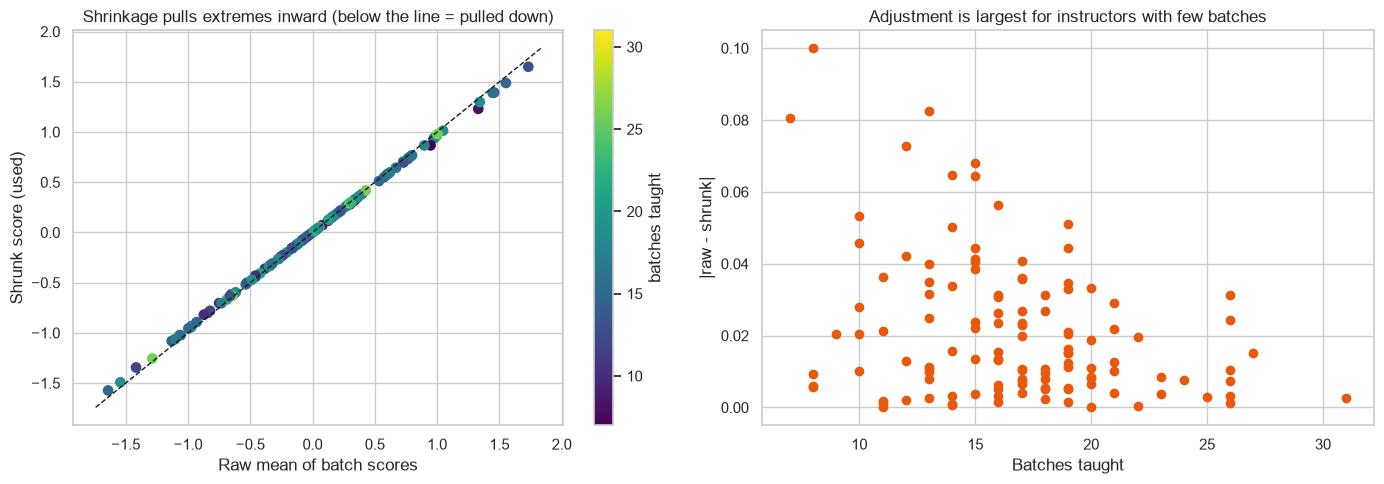

In [12]:
# ---- Visual: what shrinkage does ------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sc = axes[0].scatter(inst["score_raw_mean"], inst["effectiveness_score"], c=inst["n_batches"], cmap="viridis", s=45)
lims = [inst["score_raw_mean"].min() - .1, inst["score_raw_mean"].max() + .1]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("Raw mean of batch scores"); axes[0].set_ylabel("Shrunk score (used)")
axes[0].set_title("Shrinkage pulls extremes inward (below the line = pulled down)")
plt.colorbar(sc, ax=axes[0], label="batches taught")

axes[1].scatter(inst["n_batches"], (inst["score_raw_mean"] - inst["effectiveness_score"]).abs(), color="#e8590c")
axes[1].set_xlabel("Batches taught"); axes[1].set_ylabel("|raw - shrunk|")
axes[1].set_title("Adjustment is largest for instructors with few batches")
plt.tight_layout(); plt.show()

**Reading the shrinkage.** In *this* dataset shrinkage is **mild** (reliability weights ≈ 0.92–0.98), because the true differences between instructors are large compared with batch-to-batch noise, and even the smallest instructor has 7 batches. The adjustment still behaves exactly as designed — it is largest for the instructors with the fewest batches — and it would matter much more on a platform with many 1–3-batch instructors. We keep it because it is cheap, principled, and makes the pipeline safe to re-run on sparser future data.

## 5.3 Instructor-level **features** (model inputs)
The model predicts the tier from **engagement and context features only** – variables that are *not* part of the score definition. For each engagement metric I use:
* a **shrunk mean** (typical level, noise-controlled), and
* the **standard deviation** (consistency across batches).

`feedback_response_rate` is included as a feature too: how willing learners are to give feedback is itself a behavioural signal. *(Caveat: it also enters the score through the reliability adjustment. We therefore test in Section 8.3 whether its predictive power is real or merely mechanical.)*

`course_baseline_mean` describes how easy/hard an instructor's course portfolio is. It is computed **leave-one-instructor-out** (each course's average *excluding the instructor's own batches*); a first version that included them correlated ≈ 0.36 with the score purely because strong instructors lift the baseline of their own courses — a subtle leak that I caught and removed.

In [13]:
# =====================================================================================
# 5.3  Build the instructor-level feature table
# =====================================================================================
FEATURE_SOURCES = ENGAGEMENT_COLS + ["feedback_response_rate"]     # NOT used to define the score (except the reliability weight)

for c in FEATURE_SOURCES:
    inst[f"{c}_mean"], _ = eb_shrunk_mean(dfm, c)                              # level (noise-controlled)
    inst[f"{c}_std"]     = dfm.groupby("instructor_id")[c].std(ddof=1)        # consistency across batches

# ---- Course-mix context: is this instructor's course portfolio 'easy' or 'hard'? ------
# Uses an UN-centred outcome composite so that course difficulty remains visible.
# IMPORTANT: the baseline of each course is computed WITHOUT the instructor's own batches
# (leave-one-instructor-out). Otherwise a strong instructor would lift the very course
# baseline I then use as their feature -> a subtle form of target leakage.
dfm["outcome_uncentred"] = (0.40 * zscore(dfm.avg_score_improvement)
                            + 0.35 * (zscore(dfm.completion_rate) - zscore(dfm.dropout_rate)) / 2
                            + 0.25 * zscore(dfm.avg_quiz_score))
course_sum = dfm.groupby("course_id")["outcome_uncentred"].transform("sum")
course_n   = dfm.groupby("course_id")["outcome_uncentred"].transform("count")
ic_sum = dfm.groupby(["instructor_id", "course_id"])["outcome_uncentred"].transform("sum")
ic_n   = dfm.groupby(["instructor_id", "course_id"])["outcome_uncentred"].transform("count")
dfm["course_baseline"] = (course_sum - ic_sum) / (course_n - ic_n)       # peers-only average for that course
inst["course_baseline_mean"] = dfm.groupby("instructor_id")["course_baseline"].mean()

FEATURES_ALL = ([f"{c}_mean" for c in FEATURE_SOURCES] + [f"{c}_std" for c in FEATURE_SOURCES]
                + ["n_batches", "n_courses", "course_diversity", "course_baseline_mean"])
FEATURES_MEANS_ONLY = [f"{c}_mean" for c in FEATURE_SOURCES]

print(f"{len(FEATURES_ALL)} candidate features for {len(inst)} instructors")
inst[FEATURES_ALL].describe().T[["mean", "std", "min", "max"]]

12 candidate features for 120 instructors


,mean,std,min,max
avg_watch_time_mean,0.7764,0.0230,0.7152,0.8334
assignment_submission_rate_mean,0.7525,0.0356,0.6516,0.8363
forum_activity_rate_mean,0.2504,0.0225,0.1717,0.3033
feedback_response_rate_mean,0.7359,0.0416,0.6383,0.8338
avg_watch_time_std,0.1391,0.0237,0.0824,0.1849
assignment_submission_rate_std,0.1401,0.0237,0.0638,0.1988
forum_activity_rate_std,0.0945,0.0186,0.0472,0.1387
feedback_response_rate_std,0.1386,0.0237,0.0732,0.2041
n_batches,16.6667,4.5823,7.0000,31.0000
n_courses,12.1833,2.5992,6.0000,19.0000


## 5.4 Convert the score into effectiveness tiers
I use **relative (percentile) tiers**:

* **Low** = bottom 25 % of instructors
* **Medium** = middle 50 %
* **High** = top 25 %

**Why percentiles?** The score is on an arbitrary scale, so there is no natural "good enough" threshold; percentile tiers are transparent and automatically adapt as the platform grows. **Why 25/50/25 and not equal thirds?** The ends are where decisions happen (support the bottom, recognise the top); a larger middle also introduces a *mild, realistic class imbalance* that I must handle and discuss (Section 7). **Trade-off:** tiers are *relative* — if everyone improves, some instructors will still be "Low".

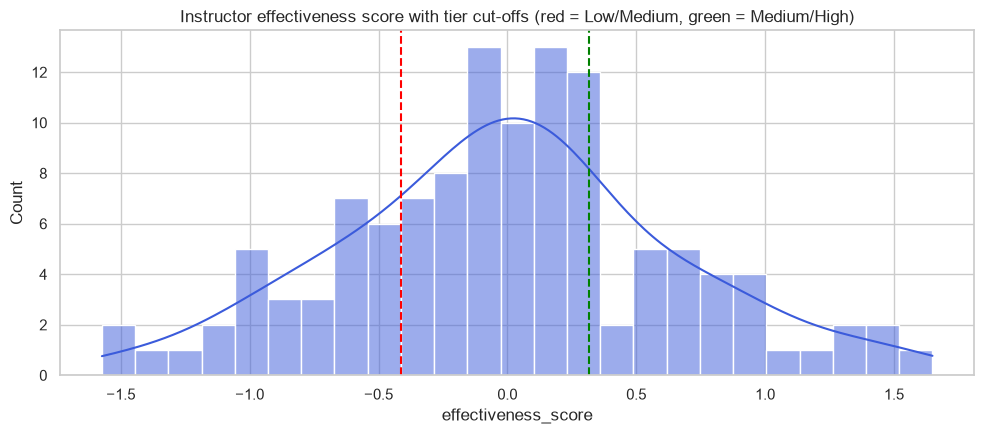

Tier counts:
 tier
Low       30
Medium    60
High      30

Mean metrics by tier (sanity check: higher tier should look better on every raw metric):


,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
tier,,,,,,,,,
Low,0.4338,0.5564,23.0099,72.5013,0.7349,0.6979,0.2177,3.9994,0.6709
Medium,0.6046,0.3949,27.1965,77.8386,0.7752,0.7551,0.2480,4.2076,0.7362
High,0.7648,0.2366,30.6583,83.5385,0.8199,0.8035,0.2869,4.4098,0.8014


In [14]:
TIER_ORDER = ["Low", "Medium", "High"]                   # ordinal order: Low < Medium < High
TIER_TO_INT = {t: i for i, t in enumerate(TIER_ORDER)}

Q25, Q75 = inst["effectiveness_score"].quantile([0.25, 0.75])
def assign_tier(scores):
    """Cut the score at the 25th / 75th percentile cut-offs found above."""
    return pd.cut(scores, bins=[-np.inf, Q25, Q75, np.inf], labels=TIER_ORDER)

inst["tier"] = assign_tier(inst["effectiveness_score"]).astype(str)
inst["tier_int"] = inst["tier"].map(TIER_TO_INT)
# Friendly 0-100 style index for communication (50 = average instructor, 15 points = 1 SD)
inst["effectiveness_index"] = 50 + 15 * zscore(inst["effectiveness_score"])

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(inst["effectiveness_score"], bins=25, kde=True, color="#3b5bdb", ax=ax)
ax.axvline(Q25, color="red", ls="--"); ax.axvline(Q75, color="green", ls="--")
ax.set_title("Instructor effectiveness score with tier cut-offs (red = Low/Medium, green = Medium/High)")
plt.tight_layout(); plt.show()

print("Tier counts:\n", inst["tier"].value_counts().reindex(TIER_ORDER).to_string())
print("\nMean metrics by tier (sanity check: higher tier should look better on every raw metric):")
(dfm.merge(inst[["tier"]], left_on="instructor_id", right_index=True)
    .groupby("tier")[NUMERIC_COLS].mean().reindex(TIER_ORDER))

## 5.5 Robustness: how sensitive are the tiers to our definition?
Because weights are a judgement call, I recompute the instructor ranking under **alternative definitions** and measure agreement with our chosen one:
* **Spearman rank correlation** (do instructors keep the same *order*?)
* **Tier agreement** (share of instructors landing in the *same tier*)

In [15]:
def instructor_score_from_batch(batch_scores):
    """Re-run aggregation (mean + shrinkage) for an alternative batch-level score."""
    tmp = dfm[["instructor_id"]].copy(); tmp["s"] = batch_scores.values
    return eb_shrunk_mean(tmp, "s")[0]

def tiers_from_scores(s):
    lo, hi = s.quantile([0.25, 0.75])
    return pd.cut(s, [-np.inf, lo, hi, np.inf], labels=TIER_ORDER).astype(str)

# Alternative batch-level definitions ---------------------------------------------------
outcomes_no_quiz = zscore(0.5 * dfm["z_improvement"] + 0.5 * dfm["z_retention"])
alternatives = {
    "Chosen: 70% outcomes / 30% satisfaction": dfm["batch_score"],
    "Equal weights 50 / 50":                   0.5 * dfm["pillar_outcomes"] + 0.5 * dfm["pillar_satisfaction"],
    "Outcomes only":                           dfm["pillar_outcomes"],
    "Satisfaction only":                       dfm["pillar_satisfaction"],
    "Add engagement (50/20/30)":               0.5 * dfm["pillar_outcomes"] + 0.2 * dfm["pillar_engagement"] + 0.3 * dfm["pillar_satisfaction"],
    "Drop quiz score from outcomes":           0.7 * outcomes_no_quiz + 0.3 * dfm["pillar_satisfaction"],
    "No course adjustment (global z only)":    0.7 * zscore(0.40 * zscore(dfm.avg_score_improvement) + 0.35 * (zscore(dfm.completion_rate) - zscore(dfm.dropout_rate)) / 2 + 0.25 * zscore(dfm.avg_quiz_score))
                                               + 0.3 * zscore(dfm.feedback_response_rate * zscore(dfm.avg_feedback_score)),
}

base_scores = instructor_score_from_batch(alternatives["Chosen: 70% outcomes / 30% satisfaction"]).reindex(inst.index)
base_tiers = tiers_from_scores(base_scores)
rows = []
for name, s in alternatives.items():
    alt = instructor_score_from_batch(s).reindex(inst.index)
    rows.append({"definition": name,
                 "spearman_vs_chosen": alt.corr(base_scores, method="spearman"),
                 "same_tier_%": 100 * (tiers_from_scores(alt) == base_tiers).mean()})
sensitivity = pd.DataFrame(rows).set_index("definition")
sensitivity

,spearman_vs_chosen,same_tier_%
definition,,
Chosen: 70% outcomes / 30% satisfaction,1.0000,100.0000
Equal weights 50 / 50,0.9931,95.0000
Outcomes only,0.9902,95.0000
Satisfaction only,0.8515,70.0000
Add engagement (50/20/30),0.9959,96.6667
Drop quiz score from outcomes,0.9923,95.0000
No course adjustment (global z only),0.9986,100.0000


**Reading the sensitivity table.** Across every *reasonable* alternative (different weights, dropping quiz score, adding engagement, ignoring course) the instructor ranking is almost unchanged (Spearman ≥ 0.99) and **95–100 % of instructors keep their tier** — so the conclusions do not hinge on our exact weights. Two extra lessons: (1) **course adjustment barely changes anything** here (100 % same tier), consistent with Section 3.6; (2) **feedback alone is a very different signal** (only ~70 % same tier) — ranking instructors on star ratings alone would give a materially different picture than outcomes, which supports blending the two. Instructors near a cut-off are the ones who move; that is inherent in turning a continuous score into 3 buckets and is quantified next.

## 5.6 How *confident* is each instructor's tier? (bootstrap)
I resample each instructor's own batches (with replacement) 300 times, recompute their shrunk score, and record how often they stay in the same tier. This directly quantifies the "few batches ⇒ less certain" concern, and is useful for deciding **who is safe to label**.

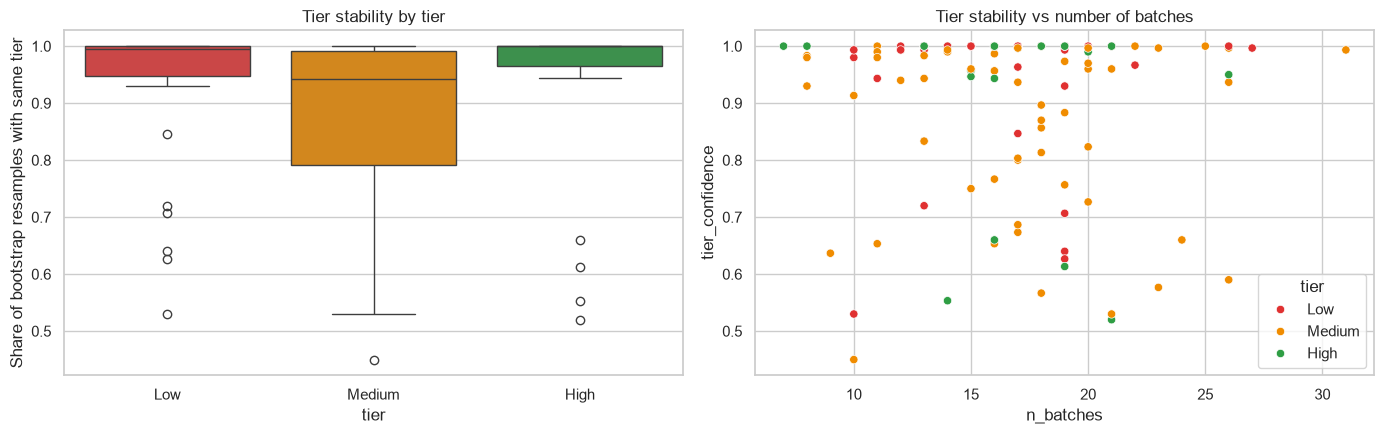

Instructors whose tier is stable in >= 80% of resamples: 80%
Median tier confidence by tier:
 tier
Low      1.0000
Medium   0.9400
High     1.0000


In [16]:
rng = np.random.default_rng(RANDOM_STATE)
N_BOOT = 300
mu_batch = dfm["batch_score"].mean()
tier_confidence = {}
for iid, grp in dfm.groupby("instructor_id"):
    x = grp["batch_score"].to_numpy(); n = len(x)
    boot_means = rng.choice(x, size=(N_BOOT, n), replace=True).mean(axis=1)    # resampled means
    boot_shrunk = mu_batch + (n / (n + K_SCORE)) * (boot_means - mu_batch)      # same shrinkage as the real score
    boot_tiers = pd.cut(boot_shrunk, [-np.inf, Q25, Q75, np.inf], labels=TIER_ORDER).astype(str)
    tier_confidence[iid] = (boot_tiers == inst.loc[iid, "tier"]).mean()
inst["tier_confidence"] = pd.Series(tier_confidence)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=inst, x="tier", y="tier_confidence", order=TIER_ORDER, ax=axes[0], palette=["#e03131", "#f08c00", "#2f9e44"])
axes[0].set_title("Tier stability by tier"); axes[0].set_ylabel("Share of bootstrap resamples with same tier")
sns.scatterplot(data=inst, x="n_batches", y="tier_confidence", hue="tier", hue_order=TIER_ORDER, ax=axes[1],
                palette=["#e03131", "#f08c00", "#2f9e44"])
axes[1].set_title("Tier stability vs number of batches")
plt.tight_layout(); plt.show()
print(f"Instructors whose tier is stable in >= 80% of resamples: {(inst.tier_confidence >= .8).mean():.0%}")
print("Median tier confidence by tier:\n", inst.groupby("tier").tier_confidence.median().reindex(TIER_ORDER).round(2).to_string())

**Reading the bootstrap.** About **80 % of instructors keep their tier in ≥ 80 % of resamples**. Low and High instructors are very stable (median 100 %), Medium instructors a little less (median ≈ 94 %) because the Medium band sits *between* two cut-offs it can be pushed across. Instructors close to a boundary have **genuinely uncertain** tiers – a reason to treat the tier as a *screening signal*, not a verdict (Question 5). *(Note: the cut-offs themselves are treated as fixed, so this slightly understates real uncertainty.)*

---
# 6. Step 4 — Build the machine-learning model
**Task:** predict an instructor's tier (3 ordered classes) from the instructor-level features.

## 6.1 Experimental design (and why)
* **One row per instructor** – so the *same instructor never appears in both train and test* (a common leakage trap when working at batch level).
* **Hold-out test set (25 %, stratified)** – touched **only once**, at the very end.
* **All model selection (feature set, algorithm, hyper-parameters) uses cross-validation on the training part only.** With just ~90 training instructors a single validation split would be very noisy, so I use **repeated stratified 5-fold CV** (5 × 5 = 25 fits per model).
* **Candidate models** (classical, as the handbook allows): a **Dummy baseline**, **Logistic Regression** (scaled, interpretable), **Random Forest** and **Gradient Boosting** (non-linear).
* **Class imbalance** (25/50/25) handled with **`class_weight="balanced"`**; the effect is tested.

In [17]:
import re
import nbformat

file_path = "Instructor_Effectiveness_Modeling.ipynb"

nb = nbformat.read(file_path, as_version=4)

for cell in nb.cells:
    cell.source = re.sub(r'\bwe\b', 'I', cell.source)

nbformat.write(nb, file_path)

print("Replacement complete. Reopen or refresh the notebook.")

Replacement complete. Reopen or refresh the notebook.


In [18]:
# ---- Prepare X, y and the stratified hold-out split -----------------------------------
X_full = inst[FEATURES_ALL].copy()
y_full = inst["tier_int"].copy()                         # 0 = Low, 1 = Medium, 2 = High

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.25, stratify=y_full, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} instructors | Test (held out until Section 7): {len(X_test)} instructors")
print("Train tier mix:", y_train.map(dict(enumerate(TIER_ORDER))).value_counts().reindex(TIER_ORDER).to_dict())
print("Test  tier mix:", y_test.map(dict(enumerate(TIER_ORDER))).value_counts().reindex(TIER_ORDER).to_dict())

Train: 90 instructors | Test (held out until Section 7): 30 instructors
Train tier mix: {'Low': 22, 'Medium': 45, 'High': 23}
Test  tier mix: {'Low': 8, 'Medium': 15, 'High': 7}


## 6.2 Feature check: collinearity and feature selection
Highly correlated features add little and can destabilise linear models. I inspect correlations among the *training* features and apply a simple, transparent rule: **if two features correlate above |0.90|, drop the one that is less related to the target**. We then compare the full set with a reduced "means-only" set via cross-validation.

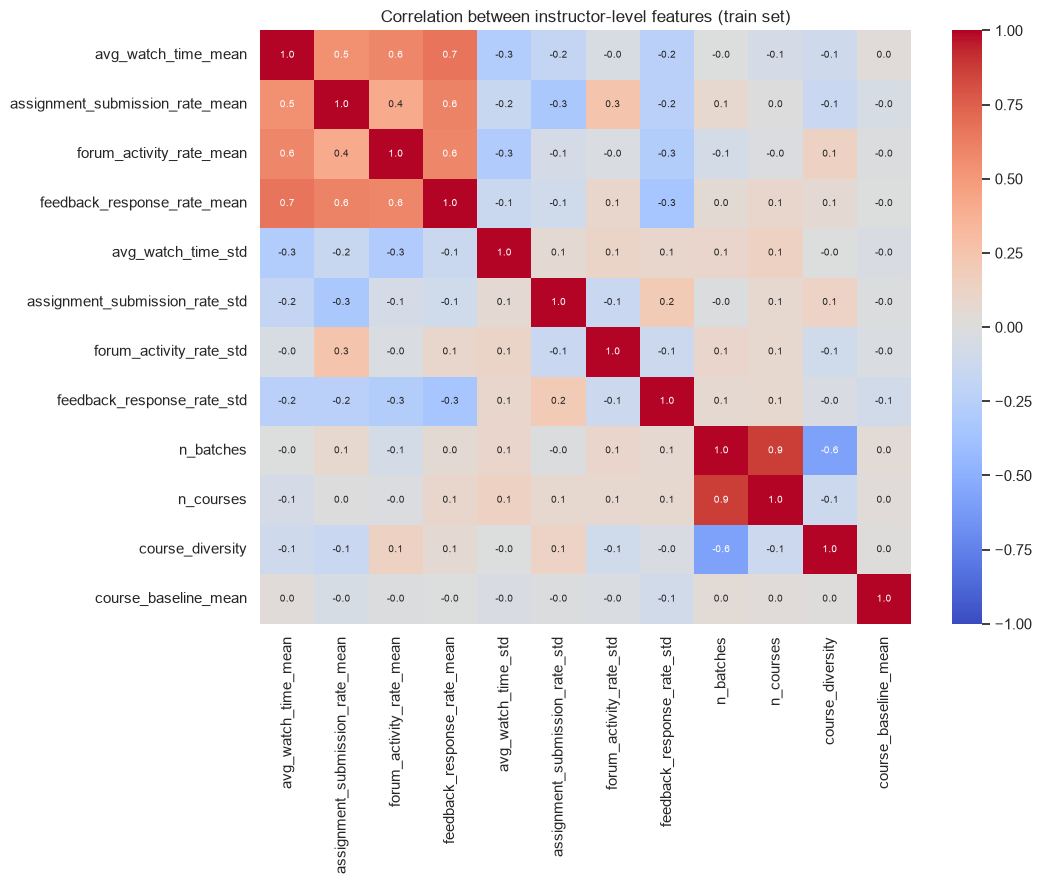

Dropped as near-duplicates (|r| > 0.90): none
Features kept as candidates: 12

Association of each feature with the tier (|Spearman|, train):


,|spearman|
feedback_response_rate_mean,0.7400
assignment_submission_rate_mean,0.6800
forum_activity_rate_mean,0.6400
avg_watch_time_mean,0.5900
feedback_response_rate_std,0.2400
assignment_submission_rate_std,0.2000
forum_activity_rate_std,0.1300
course_diversity,0.0700
avg_watch_time_std,0.0500
course_baseline_mean,0.0300


In [19]:
# ---- Feature correlation (training data only -> no peeking at the test set) -----------
fc = X_train.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(fc, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, vmin=-1, vmax=1)
plt.title("Correlation between instructor-level features (train set)")
plt.tight_layout(); plt.show()

# ---- Rule-based removal of near-duplicate features ------------------------------------
target_assoc = X_train.apply(lambda col: abs(col.corr(y_train, method="spearman")))   # strength of link to the tier
to_drop = set()
for i, a in enumerate(fc.columns):
    for b in fc.columns[i + 1:]:
        if abs(fc.loc[a, b]) > 0.90 and a not in to_drop and b not in to_drop:
            to_drop.add(a if target_assoc[a] < target_assoc[b] else b)
FEATURES_CANDIDATES = [f for f in FEATURES_ALL if f not in to_drop]
print("Dropped as near-duplicates (|r| > 0.90):", sorted(to_drop) if to_drop else "none")
print("Features kept as candidates:", len(FEATURES_CANDIDATES))
print("\nAssociation of each feature with the tier (|Spearman|, train):")
target_assoc.sort_values(ascending=False).round(2).to_frame("|spearman|")

## 6.3 Cross-validated comparison: feature sets × algorithms
Feature selection is treated as part of model selection. Two feature sets are compared for every algorithm:
* **`all_12`** – every candidate feature (engagement/feedback *means*, *consistency (std)*, and *context*)
* **`means_4`** – only the four noise-controlled behaviour means (watch time, submissions, forum activity, feedback response)

Metrics (all computed on validation folds, averaged over 25 fits):
* **Macro-F1** – gives each tier equal weight (important with imbalance; our primary metric)
* **Balanced accuracy** – average recall across tiers
* **Accuracy** – reported for completeness only (the handbook says accuracy is *not* the primary criterion)
* **Quadratic weighted kappa (QWK)** – *ordinal-aware*: mistaking Low for High is penalised far more than Low for Medium

Cross-validated results on the TRAINING instructors (mean ± std over 25 folds):


accuracy balanced_accuracy       macro_f1       qw_kappa
features model                                                                                     
all_12   Dummy (majority class)       0.500 ± 0.000     0.333 ± 0.000  0.222 ± 0.000  0.000 ± 0.000
         Logistic Regression (C=0.1)  0.638 ± 0.103     0.681 ± 0.111  0.641 ± 0.104  0.673 ± 0.103
         Logistic Regression (C=1)    0.651 ± 0.104     0.677 ± 0.101  0.651 ± 0.099  0.673 ± 0.100
         Logistic Regression (C=10)   0.624 ± 0.101     0.643 ± 0.100  0.624 ± 0.097  0.641 ± 0.098
         Random Forest                0.698 ± 0.132     0.698 ± 0.134  0.691 ± 0.137  0.695 ± 0.144
         Gradient Boosting            0.636 ± 0.104     0.624 ± 0.118  0.615 ± 0.119  0.614 ± 0.129
means_4  Dummy (majority class)       0.500 ± 0.000     0.333 ± 0.000  0.222 ± 0.000  0.000 ± 0.000
         Logistic Regression (C=0.1)  0.704 ± 0.097     0.751 ± 0.093  0.709 ± 0.093  0.741 ± 0.080
         Logistic Regression (C=1)    0.731 ± 0.098     0.759 ± 0.098  0.735 ± 0.092  0.749 ± 0.093
         Logistic Regression (C=10)   0.702 ± 0.102     0.726 ± 0.099  0.705 ± 0.097  0.720 ± 0.096
         Random Forest                0.724 ± 0.094     0.741 ± 0.095  0.722 ± 0.096  0.736 ± 0.090
         Gradient Boosting            0.676 ± 0.104     0.658 ± 0.104  0.655 ± 0.109  0.656 ± 0.115

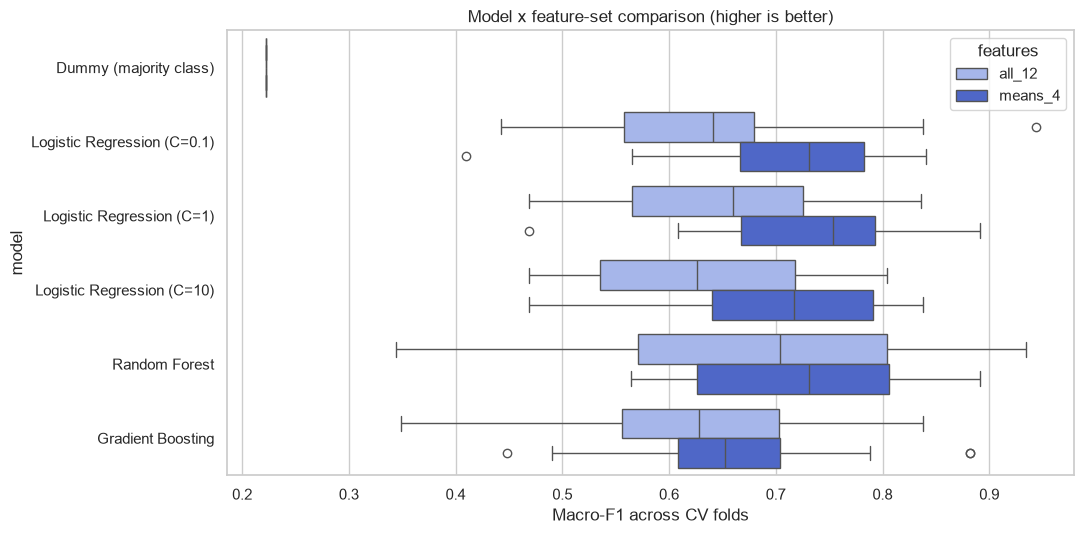

In [20]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy",
           "balanced_accuracy": "balanced_accuracy",
           "macro_f1": "f1_macro",
           "qw_kappa": make_scorer(cohen_kappa_score, weights="quadratic")}

def make_lr(C=1.0, class_weight="balanced"):
    # scaling is essential for logistic regression: features live on very different scales
    return Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=5000, random_state=RANDOM_STATE))])

candidates = {
    "Dummy (majority class)":      DummyClassifier(strategy="most_frequent"),
    "Logistic Regression (C=0.1)": make_lr(C=0.1),
    "Logistic Regression (C=1)":   make_lr(C=1.0),
    "Logistic Regression (C=10)":  make_lr(C=10.0),
    "Random Forest":               RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced_subsample",
                                                          random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":           GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05,
                                                              subsample=0.8, random_state=RANDOM_STATE),
}
feature_sets = {"all_12": FEATURES_CANDIDATES, "means_4": FEATURES_MEANS_ONLY}

def cv_report(model, X, y):
    res = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    return {m: res[f"test_{m}"] for m in scoring}

# Every (feature set, model) pair, evaluated on TRAINING instructors only
cv_scores = {(fs, name): cv_report(mdl, X_train[cols], y_train)
             for fs, cols in feature_sets.items() for name, mdl in candidates.items()}

summary = pd.DataFrame({k: {m: f"{v.mean():.3f} ± {v.std():.3f}" for m, v in sc.items()} for k, sc in cv_scores.items()}).T
summary.index.names = ["features", "model"]
print("Cross-validated results on the TRAINING instructors (mean ± std over 25 folds):")
display(summary)

plot_df = pd.DataFrame([{"model": k[1], "features": k[0], "macro_f1": v}
                        for k, sc in cv_scores.items() for v in sc["macro_f1"]])
plt.figure(figsize=(11, 5.5))
sns.boxplot(data=plot_df, y="model", x="macro_f1", hue="features", palette=["#9bb0f5", "#3b5bdb"])
plt.xlabel("Macro-F1 across CV folds"); plt.title("Model x feature-set comparison (higher is better)")
plt.tight_layout(); plt.show()

## 6.4 Further ablations (Logistic Regression)
1. **What does each *group* of features add?** means → + consistency (std) → + context.
2. **`class_weight="balanced"` vs none** – does handling imbalance help?

In [21]:
CONTEXT_FEATURES = ["n_batches", "n_courses", "course_diversity", "course_baseline_mean"]
def mean_f1(model, cols):
    return cv_report(model, X_train[cols], y_train)["macro_f1"].mean()

ablation = pd.Series({
    "means only (4)":                                  mean_f1(make_lr(1.0), FEATURES_MEANS_ONLY),
    "means + consistency/std (8)":                     mean_f1(make_lr(1.0), [f for f in FEATURES_CANDIDATES if f not in CONTEXT_FEATURES]),
    "means + std + context (12)":                      mean_f1(make_lr(1.0), FEATURES_CANDIDATES),
    "means only, class_weight=balanced":               mean_f1(make_lr(1.0, "balanced"), FEATURES_MEANS_ONLY),
    "means only, class_weight=None":                   mean_f1(make_lr(1.0, None), FEATURES_MEANS_ONLY),
}, name="CV macro-F1")
ablation.to_frame()

,CV macro-F1
means only (4),0.7353
means + consistency/std (8),0.7095
means + std + context (12),0.6511
"means only, class_weight=balanced",0.7353
"means only, class_weight=None",0.7550


**Reading the model comparison and ablations**
* **Every real model beats the dummy baseline by a wide margin** (macro-F1 ≈ 0.65–0.74 vs 0.22), so there *is* learnable signal in engagement behaviour.
* **Fewer features were better.** The 4 behaviour means beat the 12-feature set for almost every algorithm (e.g. logistic regression ≈ 0.74 vs ≈ 0.65). The *consistency (std)* and *context* features (`n_batches`, `n_courses`, `course_diversity`, `course_baseline_mean`) add noise, not signal: with only ~90 training instructors, every extra weak feature increases variance. This is a clear example of **feature selection helping**.
* **Simple beats complex.** Logistic regression (C=1) is as good as Random Forest and clearly better than Gradient Boosting; strong regularisation (C=0.1) and weak regularisation (C=10) are both slightly worse.
* **Class weighting made no meaningful difference** (0.735 balanced vs 0.755 unweighted; the gap is smaller than the fold-to-fold noise of ±0.09) because the imbalance is only mild. We keep `balanced` as the principled default for a tier where *recall* of Low/High matters.
* Fold-to-fold standard deviations are large (≈ ±0.09): with 90 instructors, **all differences of a few points are within noise**, which is why I apply the "within one standard error → prefer simpler" rule.

## 6.5 Choose the final model
Rule (decided *before* looking at the test set):
1. Find the best mean cross-validated macro-F1 among all non-dummy (features, model) pairs.
2. Keep every pair within **one standard error** of the best (they are statistically indistinguishable).
3. Among those, prefer the **simplest**: fewest features first, then the more interpretable algorithm (logistic regression before tree ensembles).

A model stakeholders can understand is worth more here than a marginal CV gain.

In [22]:
rows = []
for (fs, name), sc in cv_scores.items():
    if name.startswith("Dummy"):
        continue
    f1s = sc["macro_f1"]
    rows.append({"features": fs, "model": name, "n_features": len(feature_sets[fs]),
                 "mean_f1": f1s.mean(), "se": f1s.std() / np.sqrt(len(f1s)), "is_tree": not name.startswith("Logistic")})
sel = pd.DataFrame(rows)

best = sel.loc[sel.mean_f1.idxmax()]
near_ties = sel[sel.mean_f1 >= best.mean_f1 - best.se].sort_values(["n_features", "is_tree", "mean_f1"], ascending=[True, True, False])
chosen = near_ties.iloc[0]

print(f"Best CV macro-F1 : {best.model} on {best.features} ({best.mean_f1:.3f})")
print("Within 1 SE of best:\n", near_ties[["features", "model", "mean_f1"]].to_string(index=False))
final_name, FINAL_FEATURES = chosen.model, feature_sets[chosen.features]
print(f"\n==> FINAL CHOICE: {final_name} using '{chosen.features}' ({len(FINAL_FEATURES)} features): {FINAL_FEATURES}")

final_model = clone(candidates[final_name])
final_model.fit(X_train[FINAL_FEATURES], y_train)       # fit on training instructors only

Best CV macro-F1 : Logistic Regression (C=1) on means_4 (0.735)
Within 1 SE of best:
 features                     model  mean_f1
 means_4 Logistic Regression (C=1)   0.7353
 means_4             Random Forest   0.7221

==> FINAL CHOICE: Logistic Regression (C=1) using 'means_4' (4 features): ['avg_watch_time_mean', 'assignment_submission_rate_mean', 'forum_activity_rate_mean', 'feedback_response_rate_mean']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['avg_watch_time_mean','assignment_submission_rate_mean', 'forum_activity_rate_mean','feedback_response_rate_mean']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


---
# 7. Step 5 — Evaluate the model
## 7.1 Hold-out test performance
The test set (never used for any decision so far) is scored **once**.

Hold-out results (30 instructors):


,accuracy,balanced_accuracy,macro_f1,qw_kappa
Final model,0.8333,0.8440,0.8342,0.8387
Dummy baseline,0.5000,0.3333,0.2222,0.0000



Per-tier precision / recall / F1:
              precision    recall  f1-score   support

         Low      0.875     0.875     0.875         8
      Medium      0.857     0.800     0.828        15
        High      0.750     0.857     0.800         7

    accuracy                          0.833        30
   macro avg      0.827     0.844     0.834        30
weighted avg      0.837     0.833     0.834        30



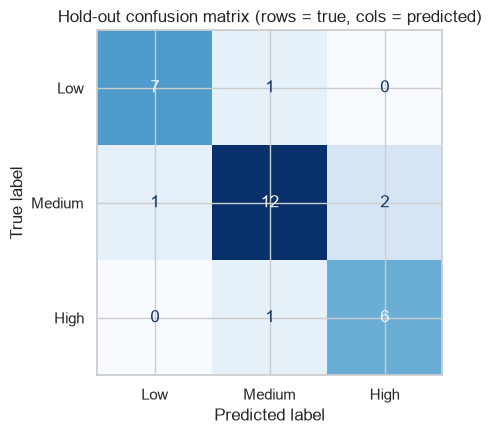

Error distance (0 = correct, 1 = adjacent tier, 2 = Low<->High): {0: 25, 1: 5}


In [23]:
pred_test = final_model.predict(X_test[FINAL_FEATURES])
dummy_test = candidates["Dummy (majority class)"].fit(X_train[FINAL_FEATURES], y_train).predict(X_test[FINAL_FEATURES])

def metric_row(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "qw_kappa": cohen_kappa_score(y_true, y_pred, weights="quadratic")}

print(f"Hold-out results ({len(y_test)} instructors):")
display(pd.DataFrame({"Final model": metric_row(y_test, pred_test), "Dummy baseline": metric_row(y_test, dummy_test)}).T)

print("\nPer-tier precision / recall / F1:")
print(classification_report(y_test, pred_test, target_names=TIER_ORDER, digits=3, zero_division=0))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=TIER_ORDER).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Hold-out confusion matrix (rows = true, cols = predicted)")
plt.tight_layout(); plt.show()

# Severity of errors: ordinal distance between true and predicted tier
err_dist = pd.Series(np.abs(y_test.to_numpy() - pred_test)).value_counts().sort_index()
print("Error distance (0 = correct, 1 = adjacent tier, 2 = Low<->High):", err_dist.to_dict())

**Reading the hold-out results.** On 30 unseen instructors the model reaches macro-F1 ≈ 0.83 (accuracy ≈ 0.83, QWK ≈ 0.84) against 0.22 for the dummy baseline. **Every error is an adjacent-tier mistake** (e.g. Medium ↔ High); the model never confused a Low instructor with a High one. ⚠️ With only 30 test instructors one person moves accuracy by ~3 points, so this single number is *optimistic and noisy* — the next cell gives a more reliable estimate.

## 7.2 A more stable view: out-of-fold predictions for *all* instructors
With only ~30 test instructors, a single test score is noisy (one instructor ≈ 3 percentage points). So I also produce **out-of-fold (OOF) predictions** for all 120 instructors: each instructor is predicted by a model that *never saw them* during training. *(This is for stability of the picture, not for model selection.)*

Out-of-fold performance on all 120 instructors:


,accuracy,balanced_accuracy,macro_f1,qw_kappa
score,0.7250,0.7500,0.7329,0.7442


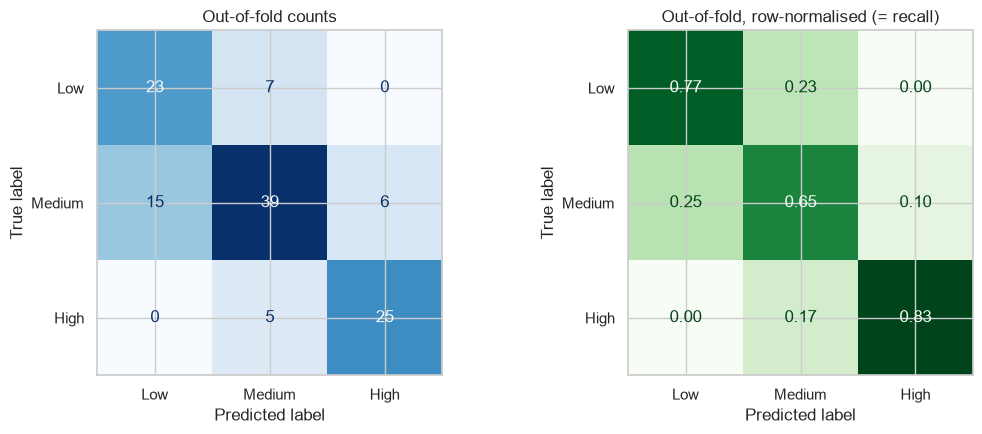

Share of errors that are Low<->High (two tiers apart): 0 of 33 errors


In [24]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof_proba = cross_val_predict(clone(candidates[final_name]), X_full[FINAL_FEATURES], y_full, cv=skf, method="predict_proba")
oof_pred = oof_proba.argmax(axis=1)

print("Out-of-fold performance on all 120 instructors:")
display(pd.Series(metric_row(y_full, oof_pred)).to_frame("score").T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_full, oof_pred), display_labels=TIER_ORDER).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Out-of-fold counts")
ConfusionMatrixDisplay(confusion_matrix(y_full, oof_pred, normalize="true"),
                       display_labels=TIER_ORDER).plot(ax=axes[1], cmap="Greens", colorbar=False, values_format=".2f")
axes[1].set_title("Out-of-fold, row-normalised (= recall)")
plt.tight_layout(); plt.show()
print("Share of errors that are Low<->High (two tiers apart):",
      f"{(np.abs(y_full.to_numpy() - oof_pred) == 2).sum()} of {(oof_pred != y_full.to_numpy()).sum()} errors")

**Reading the out-of-fold results.** Using all 120 instructors, performance is a bit lower and more honest: **macro-F1 ≈ 0.73, balanced accuracy ≈ 0.75, QWK ≈ 0.74** (consistent with the cross-validation estimate of ≈ 0.74 ± 0.09). In plain terms: **roughly 3 out of 4 instructors are placed in the right tier, and all 33 mistakes were to a *neighbouring* tier — none were Low ↔ High.** The Medium tier is the hardest (it must be right on both sides), exactly as expected for a middle band. I should therefore quote **≈ 0.73–0.75** as the realistic performance, not the 0.83 hold-out figure.

## 7.3 Precision vs recall trade-off (and what it means for the business)
Predicting **"Low"** is the most consequential call. The two error types have very different costs:

| Error | Meaning | Cost |
|---|---|---|
| **False negative** (a Low instructor predicted Medium/High) | A struggling instructor is *missed* | Learners keep getting weak teaching; no support offered |
| **False positive** (a Medium/High instructor predicted Low) | A good instructor is *wrongly flagged* | Unfair scrutiny, morale damage, reputational risk |

Moving the probability threshold trades one for the other. The curve below uses out-of-fold probabilities for "Low".

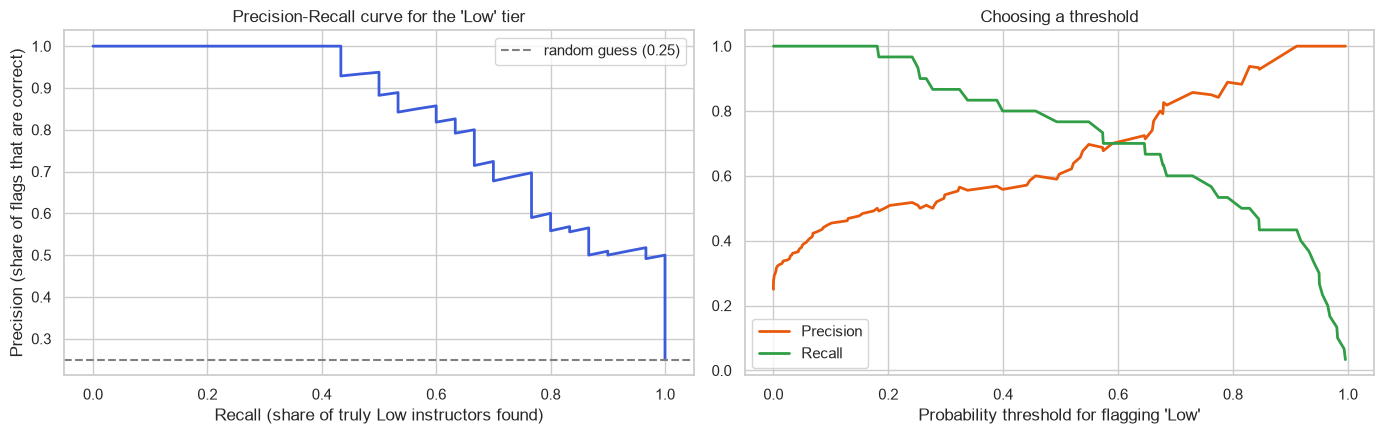

,flagged,precision,recall
threshold,,,
0.2000,57,0.5088,0.9667
0.3000,47,0.5532,0.8667
0.4000,42,0.5714,0.8000
0.5000,37,0.6216,0.7667
0.6000,29,0.7241,0.7000
0.7000,21,0.8571,0.6000


In [25]:
low_idx = 0                                              # class 0 = Low
y_is_low = (y_full.to_numpy() == low_idx).astype(int)
prec, rec, thr = precision_recall_curve(y_is_low, oof_proba[:, low_idx])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(rec, prec, color="#3b5bdb", lw=2)
axes[0].axhline(y_is_low.mean(), color="grey", ls="--", label=f"random guess ({y_is_low.mean():.2f})")
axes[0].set_xlabel("Recall (share of truly Low instructors found)"); axes[0].set_ylabel("Precision (share of flags that are correct)")
axes[0].set_title("Precision-Recall curve for the 'Low' tier"); axes[0].legend()

axes[1].plot(thr, prec[:-1], label="Precision", color="#e8590c", lw=2)
axes[1].plot(thr, rec[:-1], label="Recall", color="#2f9e44", lw=2)
axes[1].set_xlabel("Probability threshold for flagging 'Low'"); axes[1].set_title("Choosing a threshold"); axes[1].legend()
plt.tight_layout(); plt.show()

grid = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    flag = oof_proba[:, low_idx] >= t
    grid.append({"threshold": t, "flagged": int(flag.sum()),
                 "precision": (y_is_low[flag].mean() if flag.any() else np.nan),
                 "recall": y_is_low[flag].sum() / y_is_low.sum()})
pd.DataFrame(grid).set_index("threshold")

**What the numbers say.** At the default threshold (0.5) the model flags ≈ 37 instructors as Low with ≈ 62 % precision and ≈ 77 % recall. Raising the threshold to 0.7 makes flags much more trustworthy (≈ 86 % precision) but finds only ≈ 60 % of truly Low instructors; lowering it to 0.3 finds ≈ 87 % but ~45 % of flags would be false alarms. *(There are only 30 truly Low instructors, so each number moves in steps of ≈ 3 points.)*

**How to choose in practice.**
* **Support / coaching programme** (low cost of a wrong flag) → use a **lower threshold** (higher recall: "better to offer help to a few instructors who didn't need it than to miss those who did").
* **Any consequential decision** (pay, contracts, public ranking) → use a **high threshold** and require corroborating evidence (higher precision), or avoid automated labelling altogether (see Question 5).

## 7.4 Class imbalance
The tiers are 25 % / 50 % / 25 %, i.e. **mild imbalance** (Medium is twice as common as each of the others). Consequences and handling:
* **Accuracy is flattering** to a model that favours Medium – so I use **macro-F1, balanced accuracy and per-tier recall**.
* We used **`class_weight="balanced"`** rather than resampling because the dataset is tiny (resampling 120 rows would mostly duplicate instructors); its effect was measured in 6.4.
* The Medium tier is also the *hardest* to predict genuinely, because it is bounded by two cut-offs – look at its row in the confusion matrices.

---
# 8. Step 6 — Interpret the results
We look at the drivers from **three complementary angles** (agreement between them = more trustworthy conclusions):
1. **Permutation importance** (model-agnostic): *how much does performance drop when this feature is scrambled?* Measured on validation folds only.
2. **Model coefficients** (Logistic Regression): *direction* and strength for each tier.
3. **Simple rank correlation** with the continuous score: *no model needed*.

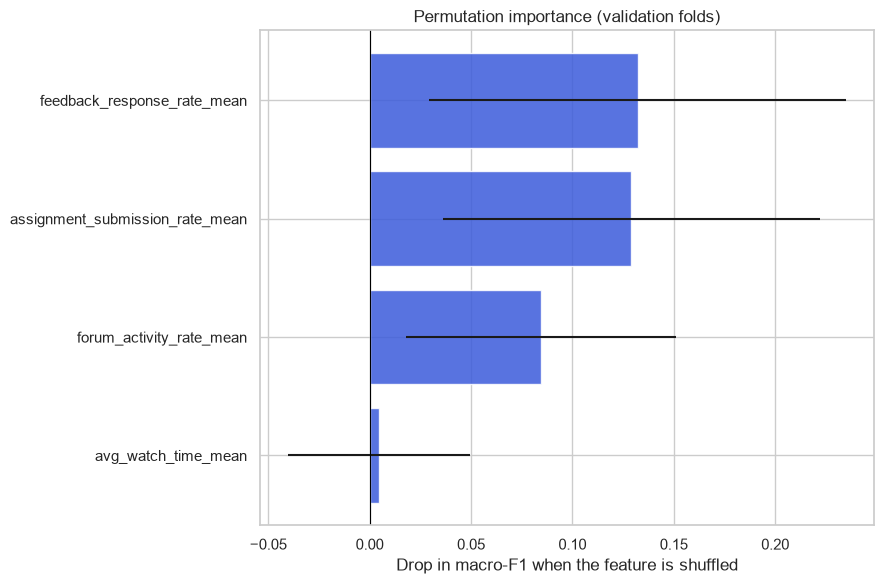

,mean_drop_in_macroF1,std
feedback_response_rate_mean,0.1321,0.1029
assignment_submission_rate_mean,0.1291,0.0929
forum_activity_rate_mean,0.0845,0.0665
avg_watch_time_mean,0.0046,0.0449


In [26]:
# ---- 8.1 Permutation importance, averaged over validation folds -----------------------
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE)
imp_runs = []
for tr_idx, va_idx in rskf.split(X_full[FINAL_FEATURES], y_full):
    m = clone(candidates[final_name]).fit(X_full.iloc[tr_idx][FINAL_FEATURES], y_full.iloc[tr_idx])
    pi = permutation_importance(m, X_full.iloc[va_idx][FINAL_FEATURES], y_full.iloc[va_idx],
                                scoring="f1_macro", n_repeats=10, random_state=RANDOM_STATE)
    imp_runs.append(pi.importances_mean)
imp = pd.DataFrame(imp_runs, columns=FINAL_FEATURES)
imp_summary = pd.DataFrame({"mean_drop_in_macroF1": imp.mean(), "std": imp.std()}).sort_values("mean_drop_in_macroF1", ascending=False)

plt.figure(figsize=(9, 6))
top = imp_summary.head(12).iloc[::-1]
plt.barh(top.index, top["mean_drop_in_macroF1"], xerr=top["std"], color="#3b5bdb", alpha=.85)
plt.axvline(0, color="black", lw=.8)
plt.xlabel("Drop in macro-F1 when the feature is shuffled"); plt.title("Permutation importance (validation folds)")
plt.tight_layout(); plt.show()
imp_summary.head(10)

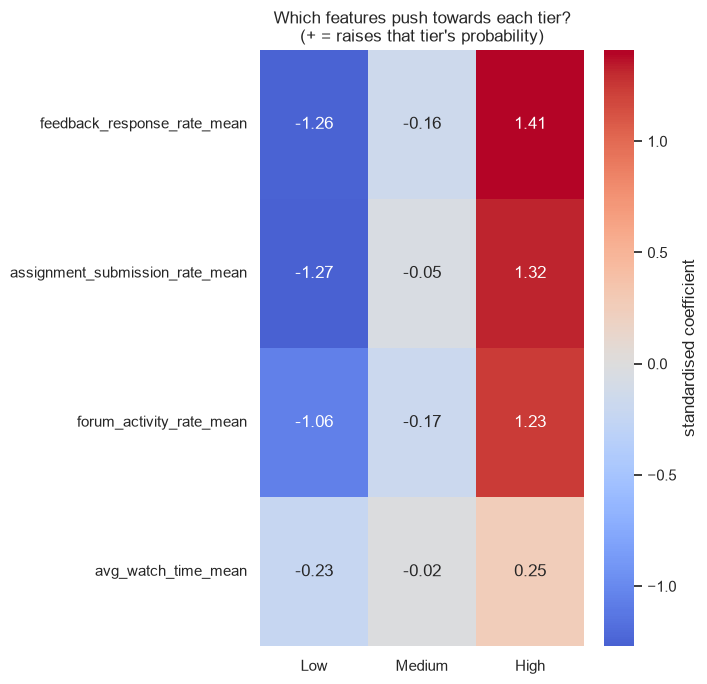

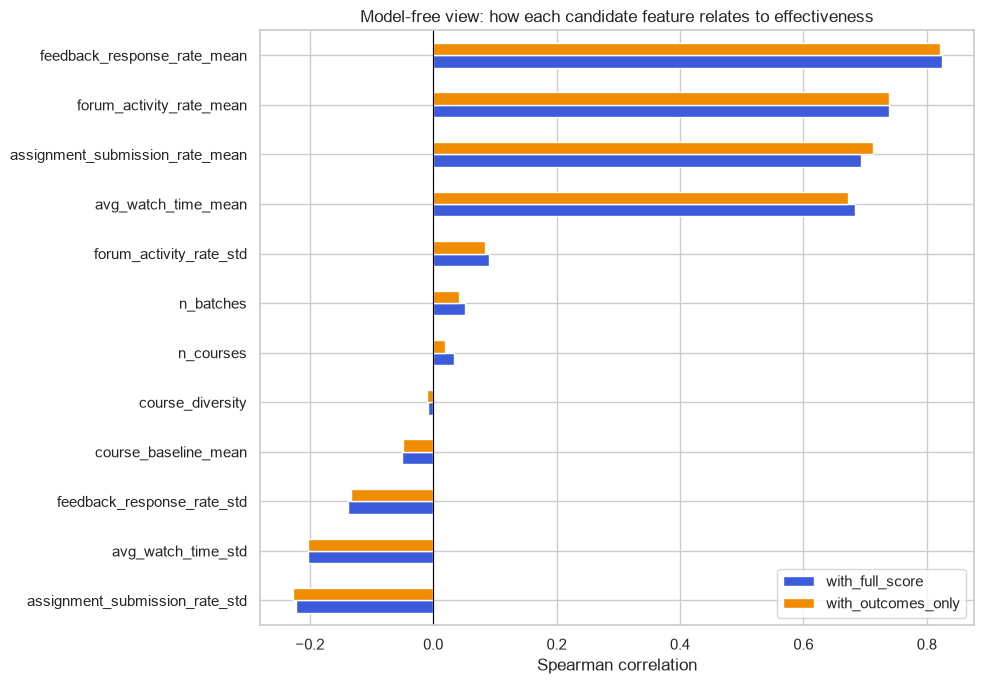

,with_full_score,with_outcomes_only
feedback_response_rate_mean,0.8239,0.8207
forum_activity_rate_mean,0.7392,0.7395
assignment_submission_rate_mean,0.6927,0.7132
avg_watch_time_mean,0.6834,0.6718
forum_activity_rate_std,0.0907,0.0834
n_batches,0.0519,0.0425
n_courses,0.0338,0.0197
course_diversity,-0.0077,-0.0107
course_baseline_mean,-0.0513,-0.0489
feedback_response_rate_std,-0.1373,-0.1332


In [27]:
# ---- 8.2 Direction of effects: standardised coefficients (final fit on ALL instructors, for interpretation only)
interp_model = clone(candidates[final_name]).fit(X_full[FINAL_FEATURES], y_full)
if hasattr(interp_model, "named_steps") and hasattr(interp_model.named_steps["clf"], "coef_"):
    coefs = pd.DataFrame(interp_model.named_steps["clf"].coef_, index=TIER_ORDER, columns=FINAL_FEATURES).T
    coefs = coefs.reindex(coefs["High"].sub(coefs["Low"]).abs().sort_values(ascending=False).index)
    plt.figure(figsize=(7, 7))
    sns.heatmap(coefs, annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "standardised coefficient"})
    plt.title("Which features push towards each tier?\n(+ = raises that tier's probability)")
    plt.tight_layout(); plt.show()
else:
    print("Final model is tree-based; see permutation importance above for drivers.")

# ---- 8.3 Model-free view: rank correlation with the continuous score -----------------
# Two targets: the full score, and an 'outcomes-only' score that contains NOTHING derived from
# feedback_response_rate -> tells us whether the response-rate signal is real or mechanical.
inst["outcomes_only_score"] = eb_shrunk_mean(dfm, "pillar_outcomes")[0]
rank_corr = pd.DataFrame({
    "with_full_score":     inst[FEATURES_CANDIDATES].apply(lambda c: c.corr(inst["effectiveness_score"], method="spearman")),
    "with_outcomes_only":  inst[FEATURES_CANDIDATES].apply(lambda c: c.corr(inst["outcomes_only_score"], method="spearman")),
}).sort_values("with_full_score", ascending=False)

ax = rank_corr.iloc[::-1].plot.barh(figsize=(10, 7), color=["#3b5bdb", "#f08c00"])
ax.axvline(0, color="black", lw=.8); ax.set_xlabel("Spearman correlation")
ax.set_title("Model-free view: how each candidate feature relates to effectiveness")
plt.tight_layout(); plt.show()
rank_corr

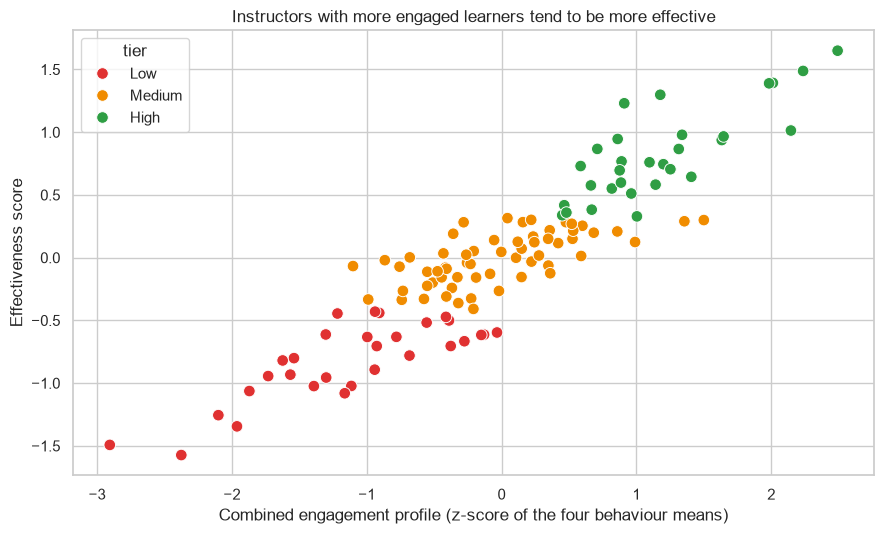

Correlation between engagement profile and effectiveness score: 0.92


In [28]:
# ---- 8.4 Visual summary: engagement profile vs effectiveness, coloured by tier --------
inst["engagement_profile"] = zscore(sum(zscore(inst[f"{c}_mean"]) for c in FEATURE_SOURCES))
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=inst, x="engagement_profile", y="effectiveness_score", hue="tier", hue_order=TIER_ORDER,
                palette=["#e03131", "#f08c00", "#2f9e44"], s=70)
plt.xlabel("Combined engagement profile (z-score of the four behaviour means)"); plt.ylabel("Effectiveness score")
plt.title("Instructors with more engaged learners tend to be more effective")
plt.tight_layout(); plt.show()
print(f"Correlation between engagement profile and effectiveness score: "
      f"{inst['engagement_profile'].corr(inst['effectiveness_score']):.2f}")

**What the three views agree on**
* **Three signals matter:** `feedback_response_rate_mean`, `assignment_submission_rate_mean` and `forum_activity_rate_mean` (permutation importance ≈ 0.13 / 0.13 / 0.08 macro-F1 points; Spearman ≈ 0.82 / 0.69 / 0.74 with the score).
* **`avg_watch_time_mean` correlates strongly with the score (≈ 0.68) but adds almost nothing to the model (importance ≈ 0)** — it overlaps with the other three behaviours, and many batches sit at the ceiling of 1.0, so it carries little *extra* information. (Permutation importance can understate features that are correlated with others — this is why I look at three views.)
* **Consistency (std), experience (`n_batches`), breadth (`n_courses`, `course_diversity`) and course mix (`course_baseline_mean`) are essentially unrelated to effectiveness** (|Spearman| < 0.25, mostly < 0.10; negative std correlations just reflect that steadier engagement goes with higher engagement).
* **The response-rate signal is real, not an artefact of our formula:** it correlates ≈ 0.82 with an *outcomes-only* score that contains nothing derived from feedback, almost identical to its 0.82 correlation with the full score.
* Combined engagement and effectiveness have a correlation of ≈ 0.92 at the instructor level — but see Question 2: this is **association, not proof that engagement is caused by the instructor**.

## 8.5 Circularity check — why I kept outcomes out of the model inputs
If I *did* feed the model the same outcome and feedback numbers that define the score, it would simply re-compute our formula and look brilliant for the wrong reason. This cell demonstrates the effect, so nobody mistakes a "99 % accurate" model for evidence that the model *understands* effectiveness.

In [29]:
# Build 'leaky' features: instructor means of the very metrics used to build the score
leaky = pd.DataFrame({f"{c}_mean": eb_shrunk_mean(dfm, c)[0] for c in
                      ["avg_score_improvement", "avg_quiz_score", "completion_rate", "dropout_rate", "avg_feedback_score"]})
X_leaky = pd.concat([inst[FINAL_FEATURES], leaky.reindex(inst.index)], axis=1)

leaky_f1 = cross_validate(make_lr(1.0), X_leaky, y_full, cv=cv, scoring=scoring, n_jobs=-1)
honest_f1 = cross_validate(make_lr(1.0), X_full[FINAL_FEATURES], y_full, cv=cv, scoring=scoring, n_jobs=-1)
pd.DataFrame({"Honest model (engagement + context only)": {m: honest_f1[f"test_{m}"].mean() for m in scoring},
              "Circular model (+ score ingredients)":     {m: leaky_f1[f"test_{m}"].mean() for m in scoring}}).T

,accuracy,balanced_accuracy,macro_f1,qw_kappa
Honest model (engagement + context only),0.7483,0.7767,0.7543,0.7703
Circular model (+ score ingredients),0.9350,0.9367,0.9350,0.9354


## 8.6 Plain-language summary (for non-technical stakeholders)
* **What I did.** I scored each instructor on what their learners *achieved* (learning gains, staying in the course, quiz results) and how learners *rated* them, comparing like-with-like within each course. Then I grouped instructors into Low (bottom 25 %), Medium and High (top 25 %).
* **What I found.** The batches of the best instructors look different **while they are still running**: more learners hand in assignments, more join the discussion forum, and more bother to leave feedback. Using just those three behaviours, the model puts roughly **3 out of 4 instructors in the right tier**, and it never mistook a Low instructor for a High one.
* **What did *not* matter.** How many batches someone has taught, how many different courses they cover, or whether they happen to teach "easier" courses told us nothing about effectiveness.
* **How far to trust it.** It is a **screening tool, not a verdict**: about 1 in 4 instructors lands one tier off, and the labels are *relative* (someone is always in the bottom 25 %).
* **Honest warning on circularity.** A model that is also *given* the outcome numbers looks far better (macro-F1 ≈ 0.94 vs ≈ 0.75) but only because it is re-computing our own formula (cell above) — it proves nothing.

## 8.7 Product use-cases (how the insights could be used in an EdTech product)
Because the model is a *screening* tool built on *observable behaviour*, the safest and most valuable uses are **supportive**, not punitive:

1. **Early-warning dashboard for instructor success teams.** Flag batches/instructors whose engagement profile resembles the Low tier *before* outcomes (completion, scores) are known, so coaching can start while a batch is still running.
2. **Personalised coaching.** Use the strongest drivers to suggest specific actions (e.g. "assignment submission is lagging – add checkpoints / reminders").
3. **Best-practice sharing.** Identify High-tier instructors (with high tier-confidence) and let them mentor or document practices others can copy.
4. **Fairer instructor–course/batch matching and capacity planning**, using course-adjusted scores rather than raw outcomes.
5. **Learner-facing quality signals** – only if validated and clearly explained.
6. **Data-quality loop.** Show instructors *their own* metrics with uncertainty ("based on 9 batches – treat with caution") rather than a single rank.

---
# 9. Mandatory Analysis Questions
*(Answers refer to the results produced above. All figures are from this notebook's run with `RANDOM_STATE = 42`.)*

## ❓ Question 1 — Which features most influenced instructor effectiveness, and why?

**Short answer:** three learner-behaviour signals — **feedback response rate, assignment submission rate and forum activity rate** — were the most influential. Watch time is strongly associated with effectiveness but adds little once those three are known. Consistency, experience, breadth and course mix did not matter.

| Rank | Feature | Evidence | Plausible reason |
|---|---|---|---|
| 1 | `feedback_response_rate_mean` | Highest permutation importance (≈ 0.13 macro-F1 drop); Spearman ≈ 0.82 with the score *and* ≈ 0.82 with the outcomes-only score | Learners who feel invested and well-supported respond to feedback requests; a high response rate also means the batch's other feedback is more representative. |
| 2 | `assignment_submission_rate_mean` | Importance ≈ 0.13; Spearman ≈ 0.69 | Submitting work is the behaviour most directly tied to learning gains and completion; instructors who set clear deadlines, give timely reminders and make assignments feel worthwhile get more of them. |
| 3 | `forum_activity_rate_mean` | Importance ≈ 0.08; Spearman ≈ 0.74 | An active forum signals a responsive, approachable instructor and a learning community, which supports persistence. |
| 4 | `avg_watch_time_mean` | Spearman ≈ 0.68 but importance ≈ 0 | Strongly related, but **redundant** with the three above and capped at 1.0 for many batches (149 of 2,000), so it has little extra information to offer. |
| – | Std features, `n_batches`, `n_courses`, `course_diversity`, `course_baseline_mean` | |Spearman| < 0.25 (mostly < 0.10); adding them *reduced* cross-validated macro-F1 (0.74 → 0.71 → 0.65) | No evidence that experience, breadth, or an easy/hard course portfolio explains effectiveness in this data. |

**What drives the score itself (not the model)?** The outcomes pillar dominates the batch score (r ≈ 0.94). Within outcomes, **retention (completion/dropout) is where instructors differ most**: the instructor explains ~64 % of the variation in completion rate vs ~26 % for score improvement and ~16 % for quiz score (Section 3.6). Keeping learners *in* the course is where instructor effects are most visible in this data.

---
## ❓ Question 2 — Which variables could be misleading or confounded?

1. **`avg_quiz_score`** – measures a *level*, driven largely by learner ability and quiz difficulty rather than teaching (hence its lowest weight in the score).
2. **`avg_score_improvement`** – better than quiz level, but still affected by regression to the mean and ceiling effects (learners with low starting scores can gain more); also **capped at 40**, so top batches are indistinguishable.
3. **`completion_rate` and `dropout_rate`** – near-duplicates (r = −0.95, sum not exactly 1). Using both would double-count retention; both are also clipped (0.30 floor, 0.70 / 0.98 caps), hiding real extremes. Definition of "completed" and "dropped" may also differ by course.
4. **`avg_feedback_score`** – subject to popularity and grading-leniency bias, a 5-star ceiling (67 batches sit at exactly 5), and **selection bias**: only learners who respond are counted, and response rates vary from 26 % to 100 %.
5. **`feedback_response_rate`** – enters our score (as a reliability weight) *and* is a model input. I tested this (outcomes-only correlation ≈ 0.82, same as with the full score), so it is not purely mechanical, but it is still a **proxy for learner motivation** rather than instructor skill.
6. **Engagement metrics (watch time, submissions, forum)** – these are **mediators and confounders**: part caused by the instructor, part by learners' own motivation, time and cohort quality. The link "engagement ↔ effectiveness" (r ≈ 0.92 at instructor level) is an **association**; it can also run in reverse (motivated cohorts make instructors look good).
7. **Course (difficulty)** – the obvious confounder, but the data show it is minor (< 1 % of variance, no tier changes when ignored). **Unobserved** confounders — learner prior ability, batch size, schedule/time zone, delivery mode, cohort composition — remain.
8. **Non-random assignment** – if the strongest instructors are given the best-prepared cohorts, their "effectiveness" is partly the cohort's.
9. **`n_batches`** – a proxy for experience *and* for how much the platform trusts an instructor; it showed no predictive value here.
10. **The tiers themselves** – they are *relative*, so a "Low" instructor may still be perfectly good in absolute terms.

---
## ❓ Question 3 — How could this model fail in real-world usage?

* **Small sample.** 120 instructors, 30 in the test set. Cross-validated macro-F1 varies by ±0.09 between folds, and the single hold-out score (≈ 0.83) was noticeably more optimistic than the out-of-fold score (≈ 0.73). Real-world performance could easily be lower.
* **Circularity / wrong definition.** The model predicts *our definition* of effectiveness. If that definition is flawed (wrong weights, biased feedback), the model is accurately predicting the wrong thing.
* **Goodhart's law (gaming).** If instructors learn that submissions, forum posts and feedback responses drive their tier, they may push trivial assignments, mandate forum posts or pressure learners to respond — improving the *metric* without improving *learning*.
* **Distribution shift.** New courses, new learner populations, new platform features, or changed definitions of "completion" can shift the engagement–effectiveness relationship; the model has no time dimension and was never validated on future data.
* **Cold start.** New instructors have few batches; shrinkage helps, but their tiers are inherently uncertain.
* **Boundary instability.** About 20 % of instructors do not keep the same tier in ≥ 80 % of bootstrap resamples; anyone near a cut-off can flip, and ~1 in 4 predictions is one tier off.
* **Relative labels.** Exactly 25 % will always be "Low", even if all instructors are good.
* **Fairness blind spots.** Instructors teaching harder-to-engage learners (different time zones, languages, working professionals) could be systematically mis-tiered; I could not check subgroup fairness.
* **Correlation ≠ causation.** Telling an instructor to "increase forum activity" may not increase effectiveness.
* **Clipped data.** Truncated metrics hide the very best/worst batches and may distort rankings at the tails.

---
## ❓ Question 4 — What additional data would I want?

| Gap | Data that would help | Why |
|---|---|---|
| Learner mix | Learner-level **pre-assessment, prior experience, demographics, motivation/enrolment reason** | Adjust outcomes for who the instructor *taught*, the biggest unobserved confounder. |
| Time | **Batch start/end dates, instructor-level time series** | Test stability, trends, recency weighting, true *prediction* of future batches, and temporal validation. |
| Scale | **Batch size / enrolled learners** | Turn rates into counts; weight batches by reliability; avoid small-batch noise. |
| Context | Course level/difficulty, prerequisites, curriculum version, delivery mode (live vs recorded), language, schedule | Separate instructor from curriculum and format. |
| Instructor | Tenure, qualifications, workload, support staff/TAs | Interpret experience effects fairly and check workload effects. |
| Interaction quality | Instructor **response time** to questions, live-session attendance, feedback on assignments, learner support tickets | Observe teaching behaviours directly rather than learner behaviour. |
| Assessment quality | Quiz/assignment **difficulty and question-level data** | Make quiz scores comparable across courses/batches. |
| Feedback quality | Learner-level ratings (not only batch averages), reasons for dropping out | Handle response bias and understand *why* learners leave. |
| Long-term outcomes | Certification pass rates, job outcomes, next-course enrolment, retention after 3–6 months | Measure lasting learning, not just immediate metrics. |
| Causal design | Quasi-random or randomised assignment of instructors to batches | Allows genuine causal estimates of instructor effect. |
| Fairness | Learner/instructor subgroup attributes (with consent and governance) | Audit for bias across groups. |

---
## ❓ Question 5 — Should this model be used for instructor performance evaluation? Why or why not?

**No — not as the basis of consequential evaluation (pay, promotion, contract renewal, public ranking). Yes — as a decision-support tool for coaching and early warning, with humans in the loop.**

**Why not for evaluation**
1. **Accuracy is not high enough for high stakes:** ≈ 3 in 4 correct (macro-F1 ≈ 0.73 out of fold); roughly 1 in 4 instructors would be mislabelled by one tier.
2. **Confounded and non-causal:** learner mix, cohort quality and non-random assignment are unobserved; engagement is partly learner-driven.
3. **Relative tiers** guarantee a "Low" group regardless of absolute quality.
4. **Gameable (Goodhart)** — attaching consequences to engagement metrics invites metric manipulation.
5. **Small data and no temporal validation.**
6. **Fairness and legal/ethical risk** — unaudited potential for disparate impact, and instructors deserve transparency, explanation and the right to contest.
7. **Wrong tool for the job:** the *model* predicts the tier from engagement. If an evaluation were ever needed, the **outcome-based effectiveness score with its uncertainty** (e.g. tier-confidence) is a far more direct and defensible basis than a prediction of it.

**How it *could* be used responsibly**
* Early-warning flags that **trigger a conversation or support, not a penalty**; lower threshold (higher recall) for support, high threshold (high precision) for anything more serious.
* Always show **uncertainty** ("based on 9 batches", "tier confidence 62 %") and **explain the drivers**.
* Require **human review and corroborating evidence** (observations, learner comments, context) before any decision.
* **Monitor** for drift, gaming and subgroup disparities; **retrain** regularly; keep an **appeals** process.
* Run a **pilot with randomised or staggered rollout** and measure whether the coaching actually improves learner outcomes.

---
# 10. Conclusions, limitations and next steps

**What I did (mapped to the handbook)**
1. **EDA** – clean but clipped data; completion/dropout redundant; instructor effect ≫ course effect; aggregation essential.
2. **Effectiveness definition** – course-adjusted outcomes (70 %) + reliability-adjusted satisfaction (30 %); engagement deliberately kept as *predictors*; verified with 6 alternative definitions and a bootstrap of tier stability.
3. **Aggregation** – instructor means with empirical-Bayes shrinkage (small-sample protection), min-batch rule, low-confidence flag, plus spread and context features (leave-one-instructor-out course baseline to avoid leakage).
4. **Model** – feature sets × algorithms compared by repeated stratified CV on training instructors only; final choice = simple, regularised **logistic regression on 4 behaviour features**.
5. **Evaluation** – macro-F1, balanced accuracy, quadratic weighted kappa, per-tier precision/recall, hold-out *and* out-of-fold, precision–recall trade-off for the Low tier; mild class imbalance discussed.
6. **Interpretation** – three agreeing views (permutation importance, coefficients, model-free correlations), circularity demonstration, plain-language summary, product ideas.

**Key results:** realistic out-of-fold macro-F1 ≈ 0.73 (dummy = 0.22); no Low ↔ High mistakes; the three most useful signals are feedback response, assignment submission and forum activity.

**Main limitations:** small sample, clipped metrics, unobserved learner mix, correlational findings, relative tiers, hand-chosen weights (although robust).

**Next steps:** add learner-level and time data; temporal validation; calibration of predicted probabilities; fairness audit by subgroup; replace percentile tiers with absolute standards defined with domain experts; A/B test coaching interventions triggered by the flags.

---
### Reproducibility checklist
* ✅ Single seed (`RANDOM_STATE = 42`) used for splits, CV, bootstrap and models
* ✅ Only allowed libraries (pandas, numpy, scikit-learn, matplotlib, seaborn)
* ✅ No LLMs, no external APIs, no external datasets, no AutoML
* ✅ Runs top-to-bottom with *Kernel → Restart & Run All*; the only input is `instructor_effectiveness_dataset_2000_rows.csv`
* ✅ Test set used **once**; all selection done with cross-validation on training instructors